In [ ]:
from google.colab import drive
drive.mount("/content/drive")

from datetime import datetime, timezone
from pathlib import Path
import json
import os

UPSTREAM_COMMIT = "b76b93da8bd3096a99964a96ae29d46f197a0651"
PROJECT_ROOT = Path("/content/drive/MyDrive/CS2203_MuSc")
RUNS_ROOT = PROJECT_ROOT / "runs"
ACTIVE_RUN_FILE = PROJECT_ROOT / "active-e04-run.txt"

CATEGORIES = [
    "bottle", "cable", "capsule", "carpet", "grid",
    "hazelnut", "leather", "metal_nut", "pill", "screw",
    "tile", "toothbrush", "transistor", "wood", "zipper",
]

PROJECT_ROOT.mkdir(parents=True, exist_ok=True)
RUNS_ROOT.mkdir(parents=True, exist_ok=True)

if ACTIVE_RUN_FILE.is_file():
    candidate_run_id = ACTIVE_RUN_FILE.read_text(encoding="utf-8").strip()
    candidate_root = RUNS_ROOT / candidate_run_id
    if candidate_root.is_dir() and not (candidate_root / "E04_AGGREGATED.json").exists():
        RUN_ID = candidate_run_id
        print("Tiếp tục E04 Run ID đang dở:", RUN_ID)
    else:
        ACTIVE_RUN_FILE.unlink()
        RUN_ID = datetime.now().strftime("%Y%m%d_%H%M%S_E04_mvtec_top1_pooling")
        ACTIVE_RUN_FILE.write_text(RUN_ID + "\n", encoding="utf-8")
        print("Tạo E04 Run ID mới:", RUN_ID)
else:
    RUN_ID = datetime.now().strftime("%Y%m%d_%H%M%S_E04_mvtec_top1_pooling")
    ACTIVE_RUN_FILE.write_text(RUN_ID + "\n", encoding="utf-8")
    print("Tạo E04 Run ID mới:", RUN_ID)

RUN_ROOT = RUNS_ROOT / RUN_ID
CATEGORY_ROOT = RUN_ROOT / "categories"
SESSION_ID = datetime.now().strftime("%Y%m%d_%H%M%S")
SESSION_ROOT = RUN_ROOT / "sessions" / SESSION_ID

CATEGORY_ROOT.mkdir(parents=True, exist_ok=True)
SESSION_ROOT.mkdir(parents=True, exist_ok=False)

os.environ["MUSC_COMMIT"] = UPSTREAM_COMMIT
os.environ["MUSC_E04_RUN_ROOT"] = str(RUN_ROOT)
(RUN_ROOT / "run-id.txt").write_text(RUN_ID + "\n", encoding="utf-8")

print("Run root:", RUN_ROOT)
print("Session root:", SESSION_ROOT)

Mounted at /content/drive
Tiếp tục E04 Run ID đang dở: 20261016_102025_E04_mvtec_top1_pooling
Run root: /content/drive/MyDrive/CS2203_MuSc/runs/20261016_102025_E04_mvtec_top1_pooling
Session root: /content/drive/MyDrive/CS2203_MuSc/runs/20261016_102025_E04_mvtec_top1_pooling/sessions/20261017_073048


In [ ]:
import platform
import subprocess
import sys

subprocess.run(
    [
        sys.executable,
        "-m",
        "pip",
        "install",
        "-q",
        "--upgrade",
        "huggingface_hub",
        "ftfy==6.1.3",
        "openpyxl==3.1.2",
        "timm==0.9.12",
    ],
    check=True,
)

import cv2
import ftfy
import openpyxl
import sklearn
import skimage
import timm
import torch
import torchvision

assert torch.cuda.is_available(), "GPU chưa được bật trong Colab."

versions = {
    "python": sys.version,
    "platform": platform.platform(),
    "torch": torch.__version__,
    "torchvision": torchvision.__version__,
    "cuda_runtime": torch.version.cuda,
    "gpu": torch.cuda.get_device_name(0),
    "opencv": cv2.__version__,
    "ftfy": ftfy.__version__,
    "openpyxl": openpyxl.__version__,
    "scikit_learn": sklearn.__version__,
    "scikit_image": skimage.__version__,
    "timm": timm.__version__,
    "upstream_commit": UPSTREAM_COMMIT,
}

environment_text = "\n".join(f"{key}={value}" for key, value in versions.items())
(SESSION_ROOT / "environment.txt").write_text(environment_text + "\n", encoding="utf-8")
print(environment_text)
subprocess.run(["nvidia-smi"], check=True)

python=3.13.15 (main, Aug  6 2026, 11:06:22) [GCC 13.3.0]
platform=Linux-6.6.122+-x86_64-with-glibc2.39
torch=2.11.0+cu130
torchvision=0.26.0+cu130
cuda_runtime=13.0
gpu=Tesla T4
opencv=4.14.0
ftfy=6.1.2
openpyxl=3.1.2
scikit_learn=1.6.1
scikit_image=0.25.2
timm=0.9.12
upstream_commit=b76b93da8bd3096a99964a96ae29d46f197a0651


CompletedProcess(args=['nvidia-smi'], returncode=0)

In [ ]:
import shutil
import subprocess
from huggingface_hub import HfApi, hf_hub_download

HF_DATASET_REPO = "micguida1/mvtech_anomaly_detection"
HF_DATASET_REVISION = HfApi().dataset_info(HF_DATASET_REPO).sha
HF_CACHE = Path("/content/huggingface-mvtec-cache")

archive_path = hf_hub_download(
    repo_id=HF_DATASET_REPO,
    repo_type="dataset",
    filename="mvtec_anomaly_detection.tar.xz",
    revision=HF_DATASET_REVISION,
    cache_dir=HF_CACHE,
)

# Hugging Face dùng symlink trong cache. Cache phải nằm trên filesystem cục bộ,
# không đặt trong Google Drive vì DriveFS có thể biến symlink thành file pointer.
source_archive = Path(archive_path).resolve(strict=True)
local_archive = source_archive
archive_size = source_archive.stat().st_size
content_usage = shutil.disk_usage("/content")
required_free = 8 * 2**30
assert content_usage.free >= required_free, (
    "Không đủ dung lượng cục bộ để giải nén dataset. "
    f"Cần tối thiểu khoảng {required_free / 2**30:.2f} GiB trống."
)
print(f"Archive cục bộ: {archive_size / 2**30:.2f} GiB")

extract_root = Path("/content/data")
if extract_root.exists():
    shutil.rmtree(extract_root)
extract_root.mkdir(parents=True, exist_ok=False)

extract_result = subprocess.run(
    ["tar", "-xJf", str(local_archive), "-C", str(extract_root)],
    text=True,
    stdout=subprocess.PIPE,
    stderr=subprocess.STDOUT,
)
print("tar_return_code:", extract_result.returncode)
print("tar_output:", extract_result.stdout.strip() or "<empty>")
assert extract_result.returncode == 0, (
    "Giải nén thất bại. Chạy Cell 3D rồi Cell 3R ngay bên dưới."
)

expected_root = extract_root / "mvtec_anomaly_detection"
if expected_root.is_dir():
    DATA_ROOT = expected_root
else:
    candidates = [path.parent.parent for path in extract_root.rglob("bottle/test")]
    candidates = sorted(set(candidates))
    assert len(candidates) == 1, f"Không xác định được duy nhất dataset root: {candidates}"
    DATA_ROOT = candidates[0]

for category in CATEGORIES:
    for child in ["train", "test", "ground_truth"]:
        required = DATA_ROOT / category / child
        assert required.is_dir(), f"Thiếu thư mục: {required}"

DATA_SOURCE = f"huggingface:{HF_DATASET_REPO}@{HF_DATASET_REVISION}"
dataset_source_path = RUN_ROOT / "dataset-source.txt"
dataset_source_text = (
    f"source={DATA_SOURCE}\n"
    "archive=mvtec_anomaly_detection.tar.xz\n"
    f"resolved_root={DATA_ROOT}\n"
)

if dataset_source_path.exists():
    previous_lines = dataset_source_path.read_text(encoding="utf-8").splitlines()
    assert previous_lines[0] == f"source={DATA_SOURCE}", "Dataset revision đã thay đổi khi resume."
else:
    dataset_source_path.write_text(dataset_source_text, encoding="utf-8")

print("Dataset source:", DATA_SOURCE)
print("Dataset root:", DATA_ROOT)
print("Đã xác nhận đủ 15 category.")

mvtec_anomaly_detection.tar.xz: reconstructing file:   0%|          |  0.00B / 5.26GB            

mvtec_anomaly_detection.tar.xz: downloading bytes:           |  0.00B            

Archive cục bộ: 4.90 GiB
tar_return_code: 0
tar_output: <empty>
Dataset source: huggingface:micguida1/mvtech_anomaly_detection@eb692b36147a3b3f12c561b879a062104c1f20b8
Dataset root: /content/data
Đã xác nhận đủ 15 category.


In [ ]:
import shutil
import subprocess

REPO_ROOT = Path("/content/MuSc")
if REPO_ROOT.exists():
    shutil.rmtree(REPO_ROOT)

subprocess.run(
    ["git", "clone", "https://github.com/xrli-U/MuSc.git", str(REPO_ROOT)],
    check=True,
)
subprocess.run(
    ["git", "checkout", "--detach", UPSTREAM_COMMIT],
    cwd=REPO_ROOT,
    check=True,
)

actual_commit = subprocess.run(
    ["git", "rev-parse", "HEAD"],
    cwd=REPO_ROOT,
    text=True,
    stdout=subprocess.PIPE,
    check=True,
).stdout.strip()
assert actual_commit == UPSTREAM_COMMIT

entrypoint = REPO_ROOT / "examples" / "musc_main.py"
local_package = REPO_ROOT / "datasets" / "__init__.py"
source = entrypoint.read_bytes()
old_line = b"sys.path.append(os.getcwd())"
new_line = b"sys.path.insert(0, os.getcwd())"

if old_line in source:
    entrypoint.write_bytes(source.replace(old_line, new_line, 1))
elif new_line not in source:
    raise RuntimeError("Không tìm thấy dòng sys.path mong đợi trong musc_main.py")

local_package.touch(exist_ok=True)

diagnostic = subprocess.run(
    [
        sys.executable,
        "-c",
        "import datasets; print(datasets.__file__); "
        "import datasets.mvtec; print('Đã import datasets.mvtec thành công')",
    ],
    cwd=REPO_ROOT,
    text=True,
    stdout=subprocess.PIPE,
    stderr=subprocess.STDOUT,
    check=True,
)
print(diagnostic.stdout)

resolved_package = Path(diagnostic.stdout.splitlines()[0]).resolve()
assert REPO_ROOT.resolve() in resolved_package.parents

git_status = subprocess.run(
    ["git", "status", "--short"],
    cwd=REPO_ROOT,
    text=True,
    stdout=subprocess.PIPE,
    check=True,
).stdout
git_diff = subprocess.run(
    ["git", "diff", "--", "examples/musc_main.py"],
    cwd=REPO_ROOT,
    text=True,
    stdout=subprocess.PIPE,
    check=True,
).stdout

(SESSION_ROOT / "compatibility-fix.txt").write_text(
    "Reason: avoid collision with the Hugging Face datasets package.\n"
    "Effect on method: none; import resolution only.\n\n"
    + git_status
    + "\n"
    + git_diff,
    encoding="utf-8",
)
(RUN_ROOT / "upstream-commit.txt").write_text(actual_commit + "\n", encoding="utf-8")

/content/MuSc/datasets/__init__.py
Đã import datasets.mvtec thành công



41

In [ ]:
import subprocess

musc_path = REPO_ROOT / "models" / "musc.py"
source = musc_path.read_bytes()
line_ending = b"\r\n" if b"\r\n" in source else b"\n"

def encode_block(text):
    return text.encode("utf-8").replace(b"\n", line_ending)

def replace_once(data, old_text, new_text, label):
    old = encode_block(old_text)
    new = encode_block(new_text)
    if new in data:
        print(f"SKIP {label}: đã áp dụng")
        return data
    count = data.count(old)
    assert count == 1, f"Không tìm thấy duy nhất marker {label}: count={count}"
    print(f"APPLY {label}")
    return data.replace(old, new, 1)

source = replace_once(
    source,
    "import cv2\n",
    "import cv2\nimport gc\n",
    "import gc",
)

source = replace_once(
    source,
    "        anomaly_maps = anomaly_maps.cpu().numpy()\n"
    "        torch.cuda.empty_cache()\n",
    "        anomaly_maps = anomaly_maps.cpu().numpy()\n"
    "        # Release feature tensors before allocating flattened metric arrays.\n"
    "        del patch_tokens_list, Z_layers, Z, features, patch_tokens\n"
    "        del anomaly_maps_l, anomaly_maps_msm, anomaly_maps_iter\n"
    "        del image_info, image, input_image, test_dataloader, test_dataset, LNAMD_r\n"
    "        gc.collect()\n"
    "        torch.cuda.empty_cache()\n",
    "release expired feature tensors",
)

source = replace_once(
    source,
    "        ac_score = np.array(anomaly_maps).reshape(B, -1).max(-1)\n",
    "        ac_score = anomaly_maps.reshape(B, -1).max(-1)\n",
    "remove anomaly-map copy for image score",
)

source = replace_once(
    source,
    "        pr_px = np.array(anomaly_maps)\n",
    "        pr_px = anomaly_maps\n",
    "remove anomaly-map copy for pixel metrics",
)

musc_path.write_bytes(source)

memory_diff = subprocess.run(
    ["git", "diff", "--", "models/musc.py"],
    cwd=REPO_ROOT,
    text=True,
    stdout=subprocess.PIPE,
    check=True,
).stdout
assert "gc.collect()" in memory_diff
assert "ac_score = anomaly_maps.reshape" in memory_diff
assert "pr_px = anomaly_maps" in memory_diff

(SESSION_ROOT / "cpu-memory-patch.diff").write_text(memory_diff, encoding="utf-8")
print(memory_diff)

APPLY import gc
APPLY release expired feature tensors
APPLY remove anomaly-map copy for image score
APPLY remove anomaly-map copy for pixel metrics
diff --git a/models/musc.py b/models/musc.py
index 92e91d9..a94213f 100644
--- a/models/musc.py
+++ b/models/musc.py
@@ -23,6 +23,7 @@ from tqdm import tqdm
 import pickle
 import time
 import cv2
+import gc
 
 import warnings
 warnings.filterwarnings("ignore")
@@ -234,10 +235,15 @@ class MuSc():
         print('MuSc: {}ms per image'.format((end_time_all-start_time_all)*1000/dataset_num))
 
         anomaly_maps = anomaly_maps.cpu().numpy()
+        # Release feature tensors before allocating flattened metric arrays.
+        del patch_tokens_list, Z_layers, Z, features, patch_tokens
+        del anomaly_maps_l, anomaly_maps_msm, anomaly_maps_iter
+        del image_info, image, input_image, test_dataloader, test_dataset, LNAMD_r
+        gc.collect()
         torch.cuda.empty_cache()
 
         B = anomaly_maps.shape[0]   # the number of u

In [ ]:
import shutil

LOCAL_CLIP_CACHE = Path.home() / ".cache" / "clip"
DRIVE_CLIP_CACHE = PROJECT_ROOT / "cache" / "clip"
LOCAL_CLIP_CACHE.mkdir(parents=True, exist_ok=True)
DRIVE_CLIP_CACHE.mkdir(parents=True, exist_ok=True)

restored_files = []
for source_file in DRIVE_CLIP_CACHE.glob("*"):
    if source_file.is_file():
        target_file = LOCAL_CLIP_CACHE / source_file.name
        if not target_file.exists() or target_file.stat().st_size != source_file.stat().st_size:
            shutil.copy2(source_file, target_file)
        restored_files.append(target_file.name)

if restored_files:
    print("Đã khôi phục CLIP cache:", restored_files)
else:
    print("Chưa có CLIP cache trong Drive. Category đầu tiên sẽ tải weights khoảng 934 MB.")

Đã khôi phục CLIP cache: ['ViT-L-14-336px.pt']


In [ ]:
assert (REPO_ROOT / "models" / "musc.py").is_file()
assert DATA_ROOT.is_dir()
assert actual_commit == UPSTREAM_COMMIT
print("Setup dùng chung đã sẵn sàng cho E04.")

Setup dùng chung đã sẵn sàng cho E04.


In [ ]:
# cell 04 - 6
E04_CONFIG = {
    "experiment_id": "E04",
    "dataset_name": "mvtec_ad",
    "categories": CATEGORIES,
    "upstream_commit": UPSTREAM_COMMIT,
    "backbone_name": "ViT-L-14-336",
    "pretrained": "openai",
    "feature_layers": [5, 11, 17, 23],
    "img_resize": 518,
    "divide_num": 1,
    "r_list": [1, 3, 5],
    "batch_size": 4,
    "seed_in_upstream_entrypoint": 42,
    "pool_fraction": 0.01,
    "top_count_rule": "ceil(number_of_pixels * pool_fraction)",
    "variants": ["max_raw", "max_rscin", "top1_raw", "top1_rscin"],
    "primary_outcome": "macro_mean_image_auroc_top1_rscin_minus_max_rscin",
    "secondary_outcomes": ["image_ap", "image_f1_max", "paired_category_deltas"],
    "vis": False,
}

config_path = RUN_ROOT / "e04-config.json"
config_text = json.dumps(E04_CONFIG, indent=2, sort_keys=True) + "\n"
if config_path.exists():
    assert config_path.read_text(encoding="utf-8") == config_text, "E04 config đã thay đổi khi resume."
else:
    config_path.write_text(config_text, encoding="utf-8")

print(config_text)

{
  "backbone_name": "ViT-L-14-336",
  "batch_size": 4,
  "categories": [
    "bottle",
    "cable",
    "capsule",
    "carpet",
    "grid",
    "hazelnut",
    "leather",
    "metal_nut",
    "pill",
    "screw",
    "tile",
    "toothbrush",
    "transistor",
    "wood",
    "zipper"
  ],
  "dataset_name": "mvtec_ad",
  "divide_num": 1,
  "experiment_id": "E04",
  "feature_layers": [
    5,
    11,
    17,
    23
  ],
  "img_resize": 518,
  "pool_fraction": 0.01,
  "pretrained": "openai",
  "primary_outcome": "macro_mean_image_auroc_top1_rscin_minus_max_rscin",
  "r_list": [
    1,
    3,
    5
  ],
  "secondary_outcomes": [
    "image_ap",
    "image_f1_max",
    "paired_category_deltas"
  ],
  "seed_in_upstream_entrypoint": 42,
  "top_count_rule": "ceil(number_of_pixels * pool_fraction)",
  "upstream_commit": "b76b93da8bd3096a99964a96ae29d46f197a0651",
  "variants": [
    "max_raw",
    "max_rscin",
    "top1_raw",
    "top1_rscin"
  ],
  "vis": false
}



In [ ]:
# cell e04 - 7
import subprocess

musc_path = REPO_ROOT / "models" / "musc.py"
source = musc_path.read_bytes()
line_ending = b"\r\n" if b"\r\n" in source else b"\n"

def encode_block(text):
    return text.encode("utf-8").replace(b"\n", line_ending)

def replace_once(data, old_text, new_text, label):
    old = encode_block(old_text)
    new = encode_block(new_text)
    if new in data:
        print(f"SKIP {label}: đã áp dụng")
        return data
    count = data.count(old)
    assert count == 1, f"Không tìm thấy duy nhất marker {label}: count={count}"
    print(f"APPLY {label}")
    return data.replace(old, new, 1)

source = replace_once(
    source,
    "import cv2\n",
    "import cv2\nimport csv\nimport json\n",
    "E04 imports",
)

source = replace_once(
    source,
    "warnings.filterwarnings(\"ignore\")\n\n\nclass MuSc():\n",
    "warnings.filterwarnings(\"ignore\")\n\n\n"
    "def top_fraction_mean(anomaly_maps, fraction=0.01):\n"
    "    assert 0 < fraction <= 1\n"
    "    flat_scores = np.asarray(anomaly_maps).reshape(anomaly_maps.shape[0], -1)\n"
    "    top_count = max(1, int(np.ceil(flat_scores.shape[1] * fraction)))\n"
    "    pooled_scores = np.empty(flat_scores.shape[0], dtype=np.float64)\n"
    "    for index, row in enumerate(flat_scores):\n"
    "        split_index = row.size - top_count\n"
    "        pooled_scores[index] = np.partition(row, split_index)[split_index:].mean()\n"
    "    return pooled_scores, top_count\n\n\n"
    "class MuSc():\n",
    "top_fraction_mean helper",
)

source = replace_once(
    source,
    "        ac_score = anomaly_maps.reshape(B, -1).max(-1)\n",
    "        e04_scoring_started = time.time()\n"
    "        flat_scores = anomaly_maps.reshape(B, -1)\n"
    "        max_score = flat_scores.max(-1)\n"
    "        top1_score, top1_count = top_fraction_mean(anomaly_maps, fraction=0.01)\n"
    "        ac_score = max_score\n",
    "E04 pooling variants",
)

source = replace_once(
    source,
    "        scores_cls = RsCIN(ac_score, class_tokens, k_list=k_score)\n",
    "        scores_cls = RsCIN(max_score, class_tokens, k_list=k_score)\n"
    "        score_variants = {\n"
    "            'max_raw': np.asarray(max_score),\n"
    "            'max_rscin': np.asarray(scores_cls),\n"
    "            'top1_raw': np.asarray(top1_score),\n"
    "            'top1_rscin': np.asarray(RsCIN(top1_score, class_tokens, k_list=k_score)),\n"
    "        }\n",
    "E04 score matrix",
)

source = replace_once(
    source,
    "        image_metric, pixel_metric = compute_metrics(gt_sp, pr_sp, gt_px, pr_px)\n",
    "        image_metric, pixel_metric = compute_metrics(gt_sp, pr_sp, gt_px, pr_px)\n"
    "        variant_metrics = {}\n"
    "        for variant_name, variant_scores in score_variants.items():\n"
    "            if variant_name == 'max_rscin':\n"
    "                variant_image_metric = image_metric\n"
    "            else:\n"
    "                variant_image_metric, _ = compute_metrics(\n"
    "                    gt_sp, np.asarray(variant_scores), None, None\n"
    "                )\n"
    "            variant_metrics[variant_name] = {\n"
    "                'auroc_sp': float(variant_image_metric[0] * 100),\n"
    "                'f1_sp': float(variant_image_metric[1] * 100),\n"
    "                'ap_sp': float(variant_image_metric[2] * 100),\n"
    "            }\n"
    "\n"
    "        e04_scoring_seconds = time.time() - e04_scoring_started\n"
    "        e04_payload = {\n"
    "            'category': category,\n"
    "            'image_count': int(B),\n"
    "            'pixel_count_per_image': int(flat_scores.shape[1]),\n"
    "            'pool_fraction': 0.01,\n"
    "            'top_count': int(top1_count),\n"
    "            'e04_scoring_seconds': float(e04_scoring_seconds),\n"
    "            'variants': variant_metrics,\n"
    "        }\n"
    "        with open(os.path.join(self.output_dir, 'e04-metrics.json'), 'w') as stream:\n"
    "            json.dump(e04_payload, stream, indent=2)\n"
    "            stream.write('\\n')\n"
    "\n"
    "        score_path = os.path.join(self.output_dir, 'e04-per-image-scores.csv')\n"
    "        with open(score_path, 'w', newline='') as stream:\n"
    "            fieldnames = ['image_path', 'label', *score_variants.keys()]\n"
    "            writer = csv.DictWriter(stream, fieldnames=fieldnames)\n"
    "            writer.writeheader()\n"
    "            for index, image_path in enumerate(image_path_list):\n"
    "                row = {\n"
    "                    'image_path': image_path,\n"
    "                    'label': int(gt_sp[index]),\n"
    "                }\n"
    "                for variant_name, variant_scores in score_variants.items():\n"
    "                    row[variant_name] = float(variant_scores[index])\n"
    "                writer.writerow(row)\n",
    "E04 metric and score export",
)

musc_path.write_bytes(source)

syntax_check = subprocess.run(
    [sys.executable, "-m", "py_compile", str(musc_path)],
    cwd=REPO_ROOT,
    text=True,
    stdout=subprocess.PIPE,
    stderr=subprocess.STDOUT,
)
print(syntax_check.stdout)
assert syntax_check.returncode == 0, "models/musc.py không qua được syntax check."

e04_diff = subprocess.run(
    ["git", "diff", "--", "models/musc.py"],
    cwd=REPO_ROOT,
    text=True,
    stdout=subprocess.PIPE,
    check=True,
).stdout

assert "def top_fraction_mean" in e04_diff
assert "e04-per-image-scores.csv" in e04_diff
assert "score_variants" in e04_diff

(SESSION_ROOT / "e04-source.patch").write_text(e04_diff, encoding="utf-8")
(RUN_ROOT / "e04-source.patch").write_text(e04_diff, encoding="utf-8")
print(e04_diff)

APPLY E04 imports
APPLY top_fraction_mean helper
APPLY E04 pooling variants
APPLY E04 score matrix
APPLY E04 metric and score export

diff --git a/models/musc.py b/models/musc.py
index 92e91d9..7fff877 100644
--- a/models/musc.py
+++ b/models/musc.py
@@ -23,11 +23,25 @@ from tqdm import tqdm
 import pickle
 import time
 import cv2
+import csv
+import json
+import gc
 
 import warnings
 warnings.filterwarnings("ignore")
 
 
+def top_fraction_mean(anomaly_maps, fraction=0.01):
+    assert 0 < fraction <= 1
+    flat_scores = np.asarray(anomaly_maps).reshape(anomaly_maps.shape[0], -1)
+    top_count = max(1, int(np.ceil(flat_scores.shape[1] * fraction)))
+    pooled_scores = np.empty(flat_scores.shape[0], dtype=np.float64)
+    for index, row in enumerate(flat_scores):
+        split_index = row.size - top_count
+        pooled_scores[index] = np.partition(row, split_index)[split_index:].mean()
+    return pooled_scores, top_count
+
+
 class MuSc():
     def __init__(self, cfg, seed=0):
 

In [ ]:
import ast
import numpy as np

musc_path = REPO_ROOT / "models" / "musc.py"
musc_tree = ast.parse(musc_path.read_text(encoding="utf-8"))
helper_node = next(
    node
    for node in musc_tree.body
    if isinstance(node, ast.FunctionDef) and node.name == "top_fraction_mean"
)

helper_module = ast.Module(body=[helper_node], type_ignores=[])
ast.fix_missing_locations(helper_module)
helper_namespace = {"np": np}
exec(compile(helper_module, str(musc_path), "exec"), helper_namespace)
top_fraction_mean = helper_namespace["top_fraction_mean"]

scores_200 = np.arange(1, 201, dtype=np.float64).reshape(1, 1, 10, 20)
pooled_200, count_200 = top_fraction_mean(scores_200, 0.01)
assert count_200 == 2
assert pooled_200[0] == 199.5

scores_250 = np.arange(1, 251, dtype=np.float64).reshape(1, 1, 10, 25)
pooled_250, count_250 = top_fraction_mean(scores_250, 0.01)
assert count_250 == 3
assert pooled_250[0] == 249.0

single = np.array([[[[3.0]]]])
pooled_single, count_single = top_fraction_mean(single, 0.01)
assert count_single == 1
assert pooled_single[0] == 3.0

try:
    top_fraction_mean(single, 0.0)
except AssertionError:
    pass
else:
    raise AssertionError("fraction=0 phải bị từ chối")

print("Đạt 4 kiểm tra pooling.")

Đạt 4 kiểm tra pooling.


In [ ]:
# cell e04-9
from datetime import datetime, timezone
import json
import pandas as pd
import shlex
import shutil
import subprocess
import time

BASELINE_METRIC_COLUMNS = [
    "auroc_px", "f1_px", "ap_px", "aupro",
    "auroc_sp", "f1_sp", "ap_sp",
]
VARIANT_METRIC_COLUMNS = ["auroc_sp", "f1_sp", "ap_sp"]

def sync_clip_cache_to_drive():
    DRIVE_CLIP_CACHE.mkdir(parents=True, exist_ok=True)
    for source_file in LOCAL_CLIP_CACHE.glob("*"):
        if source_file.is_file():
            target_file = DRIVE_CLIP_CACHE / source_file.name
            if not target_file.exists() or target_file.stat().st_size != source_file.stat().st_size:
                shutil.copy2(source_file, target_file)

def successful_attempt(category):
    category_dir = CATEGORY_ROOT / category
    success_files = sorted(category_dir.glob("attempt_*/SUCCESS.json"))
    return success_files[-1].parent if success_files else None

def run_category(category):
    assert category in CATEGORIES, f"Category không hợp lệ: {category}"

    previous_success = successful_attempt(category)
    if previous_success is not None:
        metrics = json.loads((previous_success / "metrics.json").read_text(encoding="utf-8"))
        print(f"SKIP {category}: đã thành công tại {previous_success}")
        return metrics

    category_dir = CATEGORY_ROOT / category
    category_dir.mkdir(parents=True, exist_ok=True)
    attempt_number = len(list(category_dir.glob("attempt_*"))) + 1
    attempt_root = category_dir / f"attempt_{attempt_number:02d}"
    output_root = attempt_root / "output"
    attempt_root.mkdir(parents=True, exist_ok=False)

    command = [
        sys.executable,
        "examples/musc_main.py",
        "--device", "0",
        "--data_path", str(DATA_ROOT),
        "--dataset_name", "mvtec_ad",
        "--class_name", category,
        "--backbone_name", "ViT-L-14-336",
        "--pretrained", "openai",
        "--feature_layers", "5", "11", "17", "23",
        "--img_resize", "518",
        "--divide_num", "1",
        "--r_list", "1", "3", "5",
        "--batch_size", "4",
        "--output_dir", str(output_root),
        "--vis", "False",
        "--vis_type", "whole_norm",
        "--save_excel", "True",
    ]

    command_text = shlex.join(command)
    (attempt_root / "command.sh").write_text(
        "#!/usr/bin/env bash\nset -euo pipefail\n" + command_text + "\n",
        encoding="utf-8",
    )

    started_at = datetime.now(timezone.utc)
    started = time.time()
    log_path = attempt_root / "console.log"

    print(f"START {category}, attempt {attempt_number:02d}")
    with log_path.open("w", encoding="utf-8") as log_file:
        process = subprocess.Popen(
            command,
            cwd=REPO_ROOT,
            text=True,
            stdout=subprocess.PIPE,
            stderr=subprocess.STDOUT,
            bufsize=1,
        )
        for line in process.stdout:
            print(line, end="")
            log_file.write(line)
        return_code = process.wait()

    elapsed_seconds = time.time() - started
    sync_clip_cache_to_drive()

    status = {
        "category": category,
        "attempt": attempt_number,
        "started_at_utc": started_at.isoformat(),
        "finished_at_utc": datetime.now(timezone.utc).isoformat(),
        "elapsed_seconds": elapsed_seconds,
        "return_code": return_code,
        "gpu": torch.cuda.get_device_name(0),
    }

    if return_code != 0:
        (attempt_root / "FAILED.json").write_text(
            json.dumps(status, indent=2) + "\n",
            encoding="utf-8",
        )
        raise RuntimeError(f"{category} thất bại. Xem log: {log_path}")

    result_dir = output_root / "mvtec_ad" / "ViT-L-14-336" / "imagesize518"
    result_file = result_dir / "results.xlsx"
    e04_metric_file = result_dir / "e04-metrics.json"
    e04_score_file = result_dir / "e04-per-image-scores.csv"

    for required in [result_file, e04_metric_file, e04_score_file]:
        assert required.is_file(), f"Thiếu output: {required}"

    frame = pd.read_excel(result_file)
    frame = frame.rename(columns={frame.columns[0]: "category"})
    row = frame.iloc[0]
    assert row["category"] == category

    baseline_metrics = {
        column: float(row[column])
        for column in BASELINE_METRIC_COLUMNS
    }
    e04_payload = json.loads(e04_metric_file.read_text(encoding="utf-8"))
    per_image = pd.read_csv(e04_score_file)

    assert e04_payload["category"] == category
    assert e04_payload["pool_fraction"] == 0.01
    assert e04_payload["top_count"] == 2684
    assert len(per_image) == e04_payload["image_count"]
    assert per_image["image_path"].is_unique
    assert set(per_image["label"].unique()).issubset({0, 1})
    assert set(e04_payload["variants"]) == set(E04_CONFIG["variants"])

    for metric_name in VARIANT_METRIC_COLUMNS:
        baseline_value = baseline_metrics[metric_name]
        exported_value = e04_payload["variants"]["max_rscin"][metric_name]
        assert abs(baseline_value - exported_value) <= 1e-9

    shutil.copy2(result_file, attempt_root / "results.xlsx")
    shutil.copy2(e04_metric_file, attempt_root / "e04-metrics.json")
    shutil.copy2(e04_score_file, attempt_root / "e04-per-image-scores.csv")

    metrics = {
        "category": category,
        "elapsed_seconds": elapsed_seconds,
        "attempt_root": str(attempt_root),
        "baseline": baseline_metrics,
        "e04": e04_payload,
    }
    (attempt_root / "metrics.json").write_text(
        json.dumps(metrics, indent=2) + "\n",
        encoding="utf-8",
    )
    (attempt_root / "SUCCESS.json").write_text(
        json.dumps(status, indent=2) + "\n",
        encoding="utf-8",
    )

    print(f"DONE {category}: {elapsed_seconds / 60:.2f} phút")
    display(pd.DataFrame(e04_payload["variants"]).T)
    return metrics

In [ ]:
# cell e04-10
E01_BOTTLE = {
    "auroc_px": 98.47773380618383,
    "f1_px": 79.1739992895171,
    "ap_px": 83.04497992850604,
    "aupro": 96.10450992045675,
    "auroc_sp": 99.92063492063492,
    "f1_sp": 99.21259842519686,
    "ap_sp": 99.97519841269839,
}

bottle_metrics = run_category("bottle")
bottle_deltas = {
    metric: bottle_metrics["baseline"][metric] - E01_BOTTLE[metric]
    for metric in BASELINE_METRIC_COLUMNS
}
max_bottle_delta = max(abs(value) for value in bottle_deltas.values())

print("Chênh lệch nhánh max_rscin so với E01 bottle:")
for metric, delta in bottle_deltas.items():
    print(f"  {metric}: {delta:+.6f}")

assert max_bottle_delta <= 0.05, (
    "Nhánh baseline của E04 lệch E01 quá 0,05 điểm phần trăm: "
    f"{max_bottle_delta:.6f}"
)

(RUN_ROOT / "bottle-baseline-gate.json").write_text(
    json.dumps(
        {
            "category": "bottle",
            "max_absolute_delta_from_E01": max_bottle_delta,
            "deltas": bottle_deltas,
            "status": "passed",
        },
        indent=2,
    ) + "\n",
    encoding="utf-8",
)

print("Cổng baseline đạt. Có thể chạy toàn bộ E04.")

SKIP bottle: đã thành công tại /content/drive/MyDrive/CS2203_MuSc/runs/20261016_102025_E04_mvtec_top1_pooling/categories/bottle/attempt_01
Chênh lệch nhánh max_rscin so với E01 bottle:
  auroc_px: +0.000000
  f1_px: +0.000000
  ap_px: +0.000000
  aupro: +0.000000
  auroc_sp: +0.000000
  f1_sp: +0.000000
  ap_sp: +0.000000
Cổng baseline đạt. Có thể chạy toàn bộ E04.


In [ ]:
#cell e04-10r - khi colab bị ngắt
from collections import deque

progress_rows = []
for category in CATEGORIES:
    category_dir = CATEGORY_ROOT / category
    attempts = sorted(category_dir.glob("attempt_*"))
    success = successful_attempt(category)

    if success is not None:
        status = "SUCCESS"
        latest = success
    elif attempts:
        latest = attempts[-1]
        status = "FAILED" if (latest / "FAILED.json").is_file() else "INTERRUPTED"
    else:
        latest = None
        status = "NOT_STARTED"

    progress_rows.append({
        "category": category,
        "status": status,
        "attempts": len(attempts),
        "latest_attempt": str(latest) if latest else "",
    })

progress = pd.DataFrame(progress_rows)
display(progress)
print("Category còn lại:", progress.loc[progress["status"] != "SUCCESS", "category"].tolist())

for _, row in progress.loc[progress["status"] == "INTERRUPTED"].iterrows():
    log_path = Path(row["latest_attempt"]) / "console.log"
    if log_path.is_file():
        with log_path.open("r", encoding="utf-8", errors="replace") as stream:
            print(f"\n===== Cuối log của {row['category']} =====")
            print("".join(deque(stream, maxlen=12)))

,category,status,attempts,latest_attempt
0,bottle,SUCCESS,1,/content/drive/MyDrive/CS2203_MuSc/runs/202610...
1,cable,SUCCESS,1,/content/drive/MyDrive/CS2203_MuSc/runs/202610...
2,capsule,SUCCESS,1,/content/drive/MyDrive/CS2203_MuSc/runs/202610...
3,carpet,SUCCESS,1,/content/drive/MyDrive/CS2203_MuSc/runs/202610...
4,grid,SUCCESS,1,/content/drive/MyDrive/CS2203_MuSc/runs/202610...
5,hazelnut,SUCCESS,1,/content/drive/MyDrive/CS2203_MuSc/runs/202610...
6,leather,SUCCESS,1,/content/drive/MyDrive/CS2203_MuSc/runs/202610...
7,metal_nut,SUCCESS,1,/content/drive/MyDrive/CS2203_MuSc/runs/202610...
8,pill,SUCCESS,1,/content/drive/MyDrive/CS2203_MuSc/runs/202610...
9,screw,SUCCESS,1,/content/drive/MyDrive/CS2203_MuSc/runs/202610...


Category còn lại: ['transistor', 'wood', 'zipper']


In [ ]:
#cell e04-11 - chạy hoặc resume đủ 15 category
all_metrics = {}

for index, category in enumerate(CATEGORIES, start=1):
    print(f"\n===== [{index:02d}/{len(CATEGORIES)}] {category} =====")
    all_metrics[category] = run_category(category)

print("Đã hoàn thành đủ 15 category.")


===== [01/15] bottle =====
SKIP bottle: đã thành công tại /content/drive/MyDrive/CS2203_MuSc/runs/20261016_102025_E04_mvtec_top1_pooling/categories/bottle/attempt_01

===== [02/15] cable =====
SKIP cable: đã thành công tại /content/drive/MyDrive/CS2203_MuSc/runs/20261016_102025_E04_mvtec_top1_pooling/categories/cable/attempt_01

===== [03/15] capsule =====
SKIP capsule: đã thành công tại /content/drive/MyDrive/CS2203_MuSc/runs/20261016_102025_E04_mvtec_top1_pooling/categories/capsule/attempt_01

===== [04/15] carpet =====
SKIP carpet: đã thành công tại /content/drive/MyDrive/CS2203_MuSc/runs/20261016_102025_E04_mvtec_top1_pooling/categories/carpet/attempt_01

===== [05/15] grid =====
SKIP grid: đã thành công tại /content/drive/MyDrive/CS2203_MuSc/runs/20261016_102025_E04_mvtec_top1_pooling/categories/grid/attempt_01

===== [06/15] hazelnut =====
SKIP hazelnut: đã thành công tại /content/drive/MyDrive/CS2203_MuSc/runs/20261016_102025_E04_mvtec_top1_pooling/categories/hazelnut/attempt_0

,auroc_sp,f1_sp,ap_sp
max_raw,97.708333,89.655172,96.935377
max_rscin,99.291667,94.736842,99.019395
top1_raw,98.125000,90.909091,97.558472
top1_rscin,98.833333,95.000000,98.262113



===== [14/15] wood =====
START wood, attempt 01
xFormers not available
xFormers not available
{'datasets': {'dataset_name': 'mvtec_ad', 'data_path': '/content/data', 'class_name': 'wood', 'img_resize': 518, 'divide_num': 1}, 'models': {'backbone_name': 'ViT-L-14-336', 'pretrained': 'openai', 'batch_size': 4, 'feature_layers': [5, 11, 17, 23], 'r_list': [1, 3, 5]}, 'device': '0', 'testing': {'output_dir': '/content/drive/MyDrive/CS2203_MuSc/runs/20261016_102025_E04_mvtec_top1_pooling/categories/wood/attempt_01/output', 'vis': False, 'vis_type': 'whole_norm', 'save_excel': True}}
wood

100%|██████████| 20/20 [00:19<00:00,  1.01it/s]
extract time: 250.637507136864ms per image
aggregation degree: 1
LNAMD-1: 22.351781024208552ms per image
layer-0 mutual scoring...

100%|██████████| 79/79 [00:03<00:00, 21.66it/s]
layer-1 mutual scoring...

100%|██████████| 79/79 [00:03<00:00, 21.77it/s]
layer-2 mutual scoring...

100%|██████████| 79/79 [00:03<00:00, 21.43it/s]
layer-3 mutual scoring...

100

,auroc_sp,f1_sp,ap_sp
max_raw,94.736842,96.610169,97.508457
max_rscin,98.508772,98.333333,99.524762
top1_raw,95.789474,95.867769,98.304299
top1_rscin,98.508772,98.333333,99.524762



===== [15/15] zipper =====
START zipper, attempt 01
xFormers not available
xFormers not available
{'datasets': {'dataset_name': 'mvtec_ad', 'data_path': '/content/data', 'class_name': 'zipper', 'img_resize': 518, 'divide_num': 1}, 'models': {'backbone_name': 'ViT-L-14-336', 'pretrained': 'openai', 'batch_size': 4, 'feature_layers': [5, 11, 17, 23], 'r_list': [1, 3, 5]}, 'device': '0', 'testing': {'output_dir': '/content/drive/MyDrive/CS2203_MuSc/runs/20261016_102025_E04_mvtec_top1_pooling/categories/zipper/attempt_01/output', 'vis': False, 'vis_type': 'whole_norm', 'save_excel': True}}
zipper

100%|██████████| 38/38 [00:33<00:00,  1.14it/s]
extract time: 220.8305478885474ms per image
aggregation degree: 1
LNAMD-1: 29.09450341534141ms per image
layer-0 mutual scoring...

100%|██████████| 151/151 [00:24<00:00,  6.28it/s]
layer-1 mutual scoring...

100%|██████████| 151/151 [00:24<00:00,  6.07it/s]
layer-2 mutual scoring...

100%|██████████| 151/151 [00:24<00:00,  6.17it/s]
layer-3 mutual

,auroc_sp,f1_sp,ap_sp
max_raw,98.004202,97.071130,99.474944
max_rscin,99.501050,99.166667,99.862411
top1_raw,99.474790,98.305085,99.866005
top1_rscin,99.737395,99.166667,99.929374


Đã hoàn thành đủ 15 category.


In [ ]:
#cell e04-12
records = []
variant_rows = []
baseline_rows = []
score_frames = []
missing_categories = []

for category in CATEGORIES:
    attempt_root = successful_attempt(category)
    if attempt_root is None:
        missing_categories.append(category)
        continue

    record = json.loads((attempt_root / "metrics.json").read_text(encoding="utf-8"))
    records.append(record)

    baseline_rows.append({"category": category, **record["baseline"]})
    for variant_name, values in record["e04"]["variants"].items():
        variant_rows.append({
            "category": category,
            "variant": variant_name,
            **values,
        })

    score_frame = pd.read_csv(attempt_root / "e04-per-image-scores.csv")
    score_frame.insert(0, "category", category)
    score_frames.append(score_frame)

assert not missing_categories, f"Chưa hoàn thành: {missing_categories}"
assert len(records) == 15

variant_metrics = pd.DataFrame(variant_rows)
baseline_metrics = pd.DataFrame(baseline_rows)
scores_all = pd.concat(score_frames, ignore_index=True)

assert len(variant_metrics) == 15 * 4
assert scores_all.groupby("category").size().index.tolist() == CATEGORIES

macro_summary = (
    variant_metrics
    .groupby("variant", sort=False)[VARIANT_METRIC_COLUMNS]
    .mean()
    .reindex(E04_CONFIG["variants"])
    .reset_index()
)

delta_rows = []
for category in CATEGORIES:
    current = variant_metrics[variant_metrics["category"] == category].set_index("variant")
    row = {"category": category}
    for metric in VARIANT_METRIC_COLUMNS:
        row[f"{metric}_top1_minus_max_raw"] = (
            current.loc["top1_raw", metric] - current.loc["max_raw", metric]
        )
        row[f"{metric}_top1_minus_max_rscin"] = (
            current.loc["top1_rscin", metric] - current.loc["max_rscin", metric]
        )
    delta_rows.append(row)

pooling_deltas = pd.DataFrame(delta_rows)
mean_delta = {"category": "mean"}
for column in pooling_deltas.columns[1:]:
    mean_delta[column] = pooling_deltas[column].mean()
pooling_deltas = pd.concat(
    [pooling_deltas, pd.DataFrame([mean_delta])],
    ignore_index=True,
)

E01_MEAN = {
    "auroc_px": 97.11439045595469,
    "f1_px": 62.15797111567,
    "ap_px": 62.261740752632576,
    "aupro": 93.452960337022,
    "auroc_sp": 97.73403123044086,
    "f1_sp": 97.40568733484771,
    "ap_sp": 99.05280231359009,
}

baseline_mean = baseline_metrics[BASELINE_METRIC_COLUMNS].mean()
baseline_mean_deltas = {
    metric: float(baseline_mean[metric] - E01_MEAN[metric])
    for metric in BASELINE_METRIC_COLUMNS
}
max_baseline_mean_delta = max(abs(value) for value in baseline_mean_deltas.values())
assert max_baseline_mean_delta <= 0.05, (
    "Baseline continuity lệch E01 quá 0,05 điểm phần trăm: "
    f"{max_baseline_mean_delta:.6f}"
)

variant_metrics.to_csv(RUN_ROOT / "e04-category-metrics-long.csv", index=False)
macro_summary.to_csv(RUN_ROOT / "e04-macro-summary.csv", index=False)
pooling_deltas.to_csv(RUN_ROOT / "e04-pooling-deltas.csv", index=False)
baseline_metrics.to_csv(RUN_ROOT / "e04-baseline-continuity.csv", index=False)
scores_all.to_csv(RUN_ROOT / "e04-per-image-scores-all.csv", index=False)

display(macro_summary)
display(pooling_deltas.tail(5))
print("Baseline continuity max mean delta:", max_baseline_mean_delta)
print("Tổng subprocess runtime:", sum(r["elapsed_seconds"] for r in records) / 60, "phút")

,variant,auroc_sp,f1_sp,ap_sp
0,max_raw,97.386429,96.735510,98.725792
1,max_rscin,97.734031,97.405687,99.052802
2,top1_raw,97.022677,96.879586,98.824591
3,top1_rscin,96.781102,96.974682,98.776612


,category,auroc_sp_top1_minus_max_raw,auroc_sp_top1_minus_max_rscin,f1_sp_top1_minus_max_raw,f1_sp_top1_minus_max_rscin,ap_sp_top1_minus_max_raw,ap_sp_top1_minus_max_rscin
11,toothbrush,1.111111,-0.277778,3.225806,-1.639344,0.423387,-0.107527
12,transistor,0.416667,-0.458333,1.253918,0.263158,0.623096,-0.757282
13,wood,1.052632,0.000000,-0.742401,0.000000,0.795842,0.000000
14,zipper,1.470588,0.236345,1.233955,0.000000,0.391062,0.066962
15,mean,-0.363752,-0.952929,0.144076,-0.431005,0.098799,-0.276190


Baseline continuity max mean delta: 0.0
Tổng subprocess runtime: 123.5563091913859 phút


In [ ]:
# cell e04 - 13
import numpy as np
from sklearn.metrics import precision_recall_curve

def best_f1_operating_point(labels, scores):
    labels = np.asarray(labels, dtype=np.int32)
    scores = np.asarray(scores, dtype=np.float64)
    precisions, recalls, thresholds = precision_recall_curve(labels, scores)
    denominators = precisions + recalls
    f1_values = np.divide(
        2 * precisions * recalls,
        denominators,
        out=np.zeros_like(denominators),
        where=denominators != 0,
    )
    best_index = int(np.nanargmax(f1_values))
    assert best_index < len(thresholds), "Không có threshold hữu hạn cho F1-max."
    threshold = float(thresholds[best_index])
    predictions = (scores >= threshold).astype(np.int32)
    return {
        "threshold": threshold,
        "f1": float(f1_values[best_index]),
        "tp": int(((predictions == 1) & (labels == 1)).sum()),
        "fp": int(((predictions == 1) & (labels == 0)).sum()),
        "tn": int(((predictions == 0) & (labels == 0)).sum()),
        "fn": int(((predictions == 0) & (labels == 1)).sum()),
    }

operating_rows = []
for category in CATEGORIES:
    category_scores = scores_all[scores_all["category"] == category]
    for variant in E04_CONFIG["variants"]:
        operating_rows.append({
            "category": category,
            "variant": variant,
            **best_f1_operating_point(
                category_scores["label"],
                category_scores[variant],
            ),
        })

operating_points = pd.DataFrame(operating_rows)
operating_points.to_csv(RUN_ROOT / "e04-operating-points.csv", index=False)

for variant in E04_CONFIG["variants"]:
    scores_all[f"{variant}_rank_pct"] = (
        scores_all.groupby("category")[variant]
        .rank(method="average", pct=True)
    )
    threshold_map = (
        operating_points[operating_points["variant"] == variant]
        .set_index("category")["threshold"]
    )
    scores_all[f"pred_{variant}"] = (
        scores_all[variant] >= scores_all["category"].map(threshold_map)
    )

normal_candidates = scores_all[scores_all["label"] == 0].copy()
normal_candidates["rank_drop_raw"] = (
    normal_candidates["max_raw_rank_pct"]
    - normal_candidates["top1_raw_rank_pct"]
)
normal_candidates["rank_drop_rscin"] = (
    normal_candidates["max_rscin_rank_pct"]
    - normal_candidates["top1_rscin_rank_pct"]
)
normal_candidates["resolved_fp_raw"] = (
    normal_candidates["pred_max_raw"]
    & ~normal_candidates["pred_top1_raw"]
)
normal_candidates["resolved_fp_rscin"] = (
    normal_candidates["pred_max_rscin"]
    & ~normal_candidates["pred_top1_rscin"]
)
normal_candidates["new_fp_raw"] = (
    ~normal_candidates["pred_max_raw"]
    & normal_candidates["pred_top1_raw"]
)
normal_candidates["new_fp_rscin"] = (
    ~normal_candidates["pred_max_rscin"]
    & normal_candidates["pred_top1_rscin"]
)

candidate_order = normal_candidates.sort_values(
    ["resolved_fp_rscin", "resolved_fp_raw", "rank_drop_rscin", "rank_drop_raw"],
    ascending=False,
)
candidate_order.to_csv(RUN_ROOT / "e04-normal-candidates.csv", index=False)

win_loss_rows = []
for context, top_variant, max_variant in [
    ("without_rscin", "top1_raw", "max_raw"),
    ("with_rscin", "top1_rscin", "max_rscin"),
]:
    for metric in VARIANT_METRIC_COLUMNS:
        paired = variant_metrics.pivot(index="category", columns="variant", values=metric)
        delta = paired[top_variant] - paired[max_variant]
        tolerance = 1e-9
        win_loss_rows.append({
            "context": context,
            "metric": metric,
            "wins": int((delta > tolerance).sum()),
            "ties": int((delta.abs() <= tolerance).sum()),
            "losses": int((delta < -tolerance).sum()),
            "mean_delta": float(delta.mean()),
            "median_delta": float(delta.median()),
        })

win_loss = pd.DataFrame(win_loss_rows)
win_loss.to_csv(RUN_ROOT / "e04-win-tie-loss.csv", index=False)
scores_all.to_csv(RUN_ROOT / "e04-per-image-scores-all.csv", index=False)

display(win_loss)
display(candidate_order.head(12)[[
    "category", "image_path",
    "resolved_fp_raw", "resolved_fp_rscin",
    "rank_drop_raw", "rank_drop_rscin",
    "max_raw", "top1_raw", "max_rscin", "top1_rscin",
]])

,context,metric,wins,ties,losses,mean_delta,median_delta
0,without_rscin,auroc_sp,7,4,4,-0.363752,0.000000
1,without_rscin,f1_sp,6,4,5,0.144076,0.000000
2,without_rscin,ap_sp,8,3,4,0.098799,0.009415
3,with_rscin,auroc_sp,5,4,6,-0.952929,0.000000
4,with_rscin,f1_sp,4,6,5,-0.431005,0.000000
5,with_rscin,ap_sp,5,4,6,-0.276190,0.000000


,category,image_path,resolved_fp_raw,resolved_fp_rscin,rank_drop_raw,rank_drop_rscin,max_raw,top1_raw,max_rscin,top1_rscin
420,carpet,/content/data/carpet/test/good/019.png,True,True,0.111111,0.025641,0.662991,0.487151,0.331452,0.117551
868,metal_nut,/content/data/metal_nut/test/good/004.png,False,True,0.026087,0.182609,0.578863,0.549226,0.266353,0.175940
1022,pill,/content/data/pill/test/good/005.png,False,True,0.029940,0.047904,0.538271,0.482404,0.137305,0.079388
519,grid,/content/data/grid/test/good/002.png,False,True,0.051282,0.025641,0.588200,0.536700,0.177321,0.144829
1447,transistor,/content/data/transistor/test/good/022.png,True,False,0.500000,0.430000,0.634372,0.489364,0.298788,0.075400
1446,transistor,/content/data/transistor/test/good/021.png,True,False,0.370000,0.310000,0.608286,0.489995,0.201614,0.056743
1479,transistor,/content/data/transistor/test/good/054.png,True,False,0.140000,0.240000,0.628995,0.524849,0.256438,0.108017
170,cable,/content/data/cable/test/good/027.png,True,False,0.320000,0.226667,0.644298,0.551719,0.189536,0.032963
1389,toothbrush,/content/data/toothbrush/test/good/006.png,True,False,0.095238,0.095238,0.599571,0.519210,0.282965,0.090917
1462,transistor,/content/data/transistor/test/good/037.png,True,False,0.060000,0.080000,0.618590,0.533953,0.249533,0.133864


In [ ]:
# cell e04 - 14
mean_delta_row = pooling_deltas[pooling_deltas["category"] == "mean"].iloc[0]
mean_deltas = {
    key: (value if key == "category" else float(value))
    for key, value in mean_delta_row.to_dict().items()
}

summary_lines = [
    "# E04 MVTec AD Top-1-Percent Pooling Summary",
    "",
    f"- Run ID: `{RUN_ID}`",
    "- Completed categories: 15/15",
    f"- Baseline continuity maximum mean delta: {max_baseline_mean_delta:.6f} percentage points",
    f"- Total subprocess runtime: {sum(r['elapsed_seconds'] for r in records) / 60:.2f} minutes",
    "",
    "## Macro Metrics",
    "",
    macro_summary.to_string(index=False),
    "",
    "## Mean Pooling Deltas",
    "",
]

for key, value in mean_deltas.items():
    if key != "category":
        summary_lines.append(f"- {key}: {value:+.6f}")

summary_lines.extend([
    "",
    "## Interpretation Guardrails",
    "",
    "- Pixel-level metrics are controls, not E04 outcomes.",
    "- F1-max thresholds are selected post hoc from benchmark labels.",
    "- A metric increase alone does not prove reduced isolated-noise sensitivity.",
    "- Qualitative heatmaps are required for the proposed mechanism claim.",
])

(RUN_ROOT / "E04_SUMMARY.md").write_text(
    "\n".join(summary_lines) + "\n",
    encoding="utf-8",
)

completion = {
    "run_id": RUN_ID,
    "aggregated_at_utc": datetime.now(timezone.utc).isoformat(),
    "completed_categories": 15,
    "max_baseline_mean_delta_from_E01": max_baseline_mean_delta,
    "mean_pooling_deltas": mean_deltas,
    "quantitative_status": "complete",
    "qualitative_status": "pending_candidate_review",
}
(RUN_ROOT / "E04_AGGREGATED.json").write_text(
    json.dumps(completion, indent=2) + "\n",
    encoding="utf-8",
)

if ACTIVE_RUN_FILE.is_file() and ACTIVE_RUN_FILE.read_text(encoding="utf-8").strip() == RUN_ID:
    ACTIVE_RUN_FILE.unlink()

print((RUN_ROOT / "E04_SUMMARY.md").read_text(encoding="utf-8"))

# E04 MVTec AD Top-1-Percent Pooling Summary

- Run ID: `20261016_102025_E04_mvtec_top1_pooling`
- Completed categories: 15/15
- Baseline continuity maximum mean delta: 0.000000 percentage points
- Total subprocess runtime: 123.56 minutes

## Macro Metrics

   variant  auroc_sp     f1_sp     ap_sp
   max_raw 97.386429 96.735510 98.725792
 max_rscin 97.734031 97.405687 99.052802
  top1_raw 97.022677 96.879586 98.824591
top1_rscin 96.781102 96.974682 98.776612

## Mean Pooling Deltas

- auroc_sp_top1_minus_max_raw: -0.363752
- auroc_sp_top1_minus_max_rscin: -0.952929
- f1_sp_top1_minus_max_raw: +0.144076
- f1_sp_top1_minus_max_rscin: -0.431005
- ap_sp_top1_minus_max_raw: +0.098799
- ap_sp_top1_minus_max_rscin: -0.276190

## Interpretation Guardrails

- Pixel-level metrics are controls, not E04 outcomes.
- F1-max thresholds are selected post hoc from benchmark labels.
- A metric increase alone does not prove reduced isolated-noise sensitivity.
- Qualitative heatmaps are required for the p

In [ ]:
EXPORT_ROOT = PROJECT_ROOT / "exports"
EXPORT_ROOT.mkdir(parents=True, exist_ok=True)
archive_path = shutil.make_archive(
    str(EXPORT_ROOT / RUN_ID),
    "zip",
    root_dir=RUN_ROOT,
)
print("Đã tạo ZIP:", archive_path)

Đã tạo ZIP: /content/drive/MyDrive/CS2203_MuSc/exports/20261016_102025_E04_mvtec_top1_pooling.zip


In [ ]:
from google.colab import drive
drive.mount("/content/drive", force_remount=False)

from datetime import datetime, timezone
from pathlib import Path
import json
import os

UPSTREAM_COMMIT = "b76b93da8bd3096a99964a96ae29d46f197a0651"
PROJECT_ROOT = Path("/content/drive/MyDrive/CS2203_MuSc")
RUNS_ROOT = PROJECT_ROOT / "runs"
EXPORT_ROOT = PROJECT_ROOT / "exports"
SOURCE_E04_RUN_ID = "20261016_102025_E04_mvtec_top1_pooling"
SOURCE_E04_ROOT = RUNS_ROOT / SOURCE_E04_RUN_ID
ACTIVE_Q_RUN_FILE = PROJECT_ROOT / "active-e04q-run.txt"

CATEGORIES = [
    "bottle", "cable", "capsule", "carpet", "grid",
    "hazelnut", "leather", "metal_nut", "pill", "screw",
    "tile", "toothbrush", "transistor", "wood", "zipper",
]
QUAL_CATEGORIES = ["carpet", "transistor", "screw"]

RUNS_ROOT.mkdir(parents=True, exist_ok=True)
EXPORT_ROOT.mkdir(parents=True, exist_ok=True)

if ACTIVE_Q_RUN_FILE.is_file():
    candidate_id = ACTIVE_Q_RUN_FILE.read_text(encoding="utf-8").strip()
    candidate_root = RUNS_ROOT / candidate_id
    if candidate_root.is_dir() and not (candidate_root / "E04Q_DONE.json").exists():
        RUN_ID = candidate_id
        print("Resume E04Q Run ID:", RUN_ID)
    else:
        ACTIVE_Q_RUN_FILE.unlink()
        RUN_ID = datetime.now().strftime("%Y%m%d_%H%M%S_E04Q_mvtec_pooling_qualitative")
        ACTIVE_Q_RUN_FILE.write_text(RUN_ID + "\n", encoding="utf-8")
        print("Create E04Q Run ID:", RUN_ID)
else:
    RUN_ID = datetime.now().strftime("%Y%m%d_%H%M%S_E04Q_mvtec_pooling_qualitative")
    ACTIVE_Q_RUN_FILE.write_text(RUN_ID + "\n", encoding="utf-8")
    print("Create E04Q Run ID:", RUN_ID)

RUN_ROOT = RUNS_ROOT / RUN_ID
CATEGORY_ROOT = RUN_ROOT / "categories"
SESSION_ID = datetime.now().strftime("%Y%m%d_%H%M%S")
SESSION_ROOT = RUN_ROOT / "sessions" / SESSION_ID

CATEGORY_ROOT.mkdir(parents=True, exist_ok=True)
SESSION_ROOT.mkdir(parents=True, exist_ok=False)

required_source_files = [
    "E04_AGGREGATED.json",
    "e04-source.patch",
    "e04-config.json",
    "e04-category-metrics-long.csv",
    "e04-per-image-scores-all.csv",
]
assert SOURCE_E04_ROOT.is_dir(), f"Missing source E04 run: {SOURCE_E04_ROOT}"
for name in required_source_files:
    assert (SOURCE_E04_ROOT / name).is_file(), f"Missing E04 source artifact: {name}"

(RUN_ROOT / "run-id.txt").write_text(RUN_ID + "\n", encoding="utf-8")
(RUN_ROOT / "source-e04-run-id.txt").write_text(
    SOURCE_E04_RUN_ID + "\n",
    encoding="utf-8",
)

print("E04Q root:", RUN_ROOT)
print("Source E04 root:", SOURCE_E04_ROOT)

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).
Create E04Q Run ID: 20261017_082619_E04Q_mvtec_pooling_qualitative
E04Q root: /content/drive/MyDrive/CS2203_MuSc/runs/20261017_082619_E04Q_mvtec_pooling_qualitative
Source E04 root: /content/drive/MyDrive/CS2203_MuSc/runs/20261016_102025_E04_mvtec_top1_pooling


In [ ]:
import platform
import subprocess
import sys

subprocess.run(
    [
        sys.executable,
        "-m",
        "pip",
        "install",
        "-q",
        "--upgrade",
        "huggingface_hub",
        "ftfy==6.1.3",
        "openpyxl==3.1.2",
        "timm==0.9.12",
    ],
    check=True,
)

import cv2
import ftfy
import openpyxl
import sklearn
import skimage
import timm
import torch
import torchvision

assert torch.cuda.is_available(), "GPU chưa được bật trong Colab."

versions = {
    "python": sys.version,
    "platform": platform.platform(),
    "torch": torch.__version__,
    "torchvision": torchvision.__version__,
    "cuda_runtime": torch.version.cuda,
    "gpu": torch.cuda.get_device_name(0),
    "opencv": cv2.__version__,
    "ftfy": ftfy.__version__,
    "openpyxl": openpyxl.__version__,
    "scikit_learn": sklearn.__version__,
    "scikit_image": skimage.__version__,
    "timm": timm.__version__,
    "upstream_commit": UPSTREAM_COMMIT,
}

environment_text = "\n".join(f"{key}={value}" for key, value in versions.items())
(SESSION_ROOT / "environment.txt").write_text(environment_text + "\n", encoding="utf-8")
print(environment_text)
subprocess.run(["nvidia-smi"], check=True)

python=3.13.15 (main, Aug  6 2026, 11:06:22) [GCC 13.3.0]
platform=Linux-6.6.122+-x86_64-with-glibc2.39
torch=2.11.0+cu130
torchvision=0.26.0+cu130
cuda_runtime=13.0
gpu=Tesla T4
opencv=4.14.0
ftfy=6.1.2
openpyxl=3.1.2
scikit_learn=1.6.1
scikit_image=0.25.2
timm=0.9.12
upstream_commit=b76b93da8bd3096a99964a96ae29d46f197a0651


CompletedProcess(args=['nvidia-smi'], returncode=0)

In [ ]:
import shutil
import subprocess
from huggingface_hub import HfApi, hf_hub_download

HF_DATASET_REPO = "micguida1/mvtech_anomaly_detection"
HF_DATASET_REVISION = HfApi().dataset_info(HF_DATASET_REPO).sha
HF_CACHE = Path("/content/huggingface-mvtec-cache")

archive_path = hf_hub_download(
    repo_id=HF_DATASET_REPO,
    repo_type="dataset",
    filename="mvtec_anomaly_detection.tar.xz",
    revision=HF_DATASET_REVISION,
    cache_dir=HF_CACHE,
)

# Hugging Face dùng symlink trong cache. Cache phải nằm trên filesystem cục bộ,
# không đặt trong Google Drive vì DriveFS có thể biến symlink thành file pointer.
source_archive = Path(archive_path).resolve(strict=True)
local_archive = source_archive
archive_size = source_archive.stat().st_size
content_usage = shutil.disk_usage("/content")
required_free = 8 * 2**30
assert content_usage.free >= required_free, (
    "Không đủ dung lượng cục bộ để giải nén dataset. "
    f"Cần tối thiểu khoảng {required_free / 2**30:.2f} GiB trống."
)
print(f"Archive cục bộ: {archive_size / 2**30:.2f} GiB")

extract_root = Path("/content/data")
if extract_root.exists():
    shutil.rmtree(extract_root)
extract_root.mkdir(parents=True, exist_ok=False)

extract_result = subprocess.run(
    ["tar", "-xJf", str(local_archive), "-C", str(extract_root)],
    text=True,
    stdout=subprocess.PIPE,
    stderr=subprocess.STDOUT,
)
print("tar_return_code:", extract_result.returncode)
print("tar_output:", extract_result.stdout.strip() or "<empty>")
assert extract_result.returncode == 0, (
    "Giải nén thất bại. Chạy Cell 3D rồi Cell 3R ngay bên dưới."
)

expected_root = extract_root / "mvtec_anomaly_detection"
if expected_root.is_dir():
    DATA_ROOT = expected_root
else:
    candidates = [path.parent.parent for path in extract_root.rglob("bottle/test")]
    candidates = sorted(set(candidates))
    assert len(candidates) == 1, f"Không xác định được duy nhất dataset root: {candidates}"
    DATA_ROOT = candidates[0]

for category in CATEGORIES:
    for child in ["train", "test", "ground_truth"]:
        required = DATA_ROOT / category / child
        assert required.is_dir(), f"Thiếu thư mục: {required}"

DATA_SOURCE = f"huggingface:{HF_DATASET_REPO}@{HF_DATASET_REVISION}"
dataset_source_path = RUN_ROOT / "dataset-source.txt"
dataset_source_text = (
    f"source={DATA_SOURCE}\n"
    "archive=mvtec_anomaly_detection.tar.xz\n"
    f"resolved_root={DATA_ROOT}\n"
)

if dataset_source_path.exists():
    previous_lines = dataset_source_path.read_text(encoding="utf-8").splitlines()
    assert previous_lines[0] == f"source={DATA_SOURCE}", "Dataset revision đã thay đổi khi resume."
else:
    dataset_source_path.write_text(dataset_source_text, encoding="utf-8")

print("Dataset source:", DATA_SOURCE)
print("Dataset root:", DATA_ROOT)
print("Đã xác nhận đủ 15 category.")

Archive cục bộ: 4.90 GiB
tar_return_code: 0
tar_output: <empty>
Dataset source: huggingface:micguida1/mvtech_anomaly_detection@eb692b36147a3b3f12c561b879a062104c1f20b8
Dataset root: /content/data
Đã xác nhận đủ 15 category.


In [ ]:
import shutil
import subprocess

REPO_ROOT = Path("/content/MuSc")
if REPO_ROOT.exists():
    shutil.rmtree(REPO_ROOT)

subprocess.run(
    ["git", "clone", "https://github.com/xrli-U/MuSc.git", str(REPO_ROOT)],
    check=True,
)
subprocess.run(
    ["git", "checkout", "--detach", UPSTREAM_COMMIT],
    cwd=REPO_ROOT,
    check=True,
)

actual_commit = subprocess.run(
    ["git", "rev-parse", "HEAD"],
    cwd=REPO_ROOT,
    text=True,
    stdout=subprocess.PIPE,
    check=True,
).stdout.strip()
assert actual_commit == UPSTREAM_COMMIT

entrypoint = REPO_ROOT / "examples" / "musc_main.py"
local_package = REPO_ROOT / "datasets" / "__init__.py"
source = entrypoint.read_bytes()
old_line = b"sys.path.append(os.getcwd())"
new_line = b"sys.path.insert(0, os.getcwd())"

if old_line in source:
    entrypoint.write_bytes(source.replace(old_line, new_line, 1))
elif new_line not in source:
    raise RuntimeError("Không tìm thấy dòng sys.path mong đợi trong musc_main.py")

local_package.touch(exist_ok=True)

diagnostic = subprocess.run(
    [
        sys.executable,
        "-c",
        "import datasets; print(datasets.__file__); "
        "import datasets.mvtec; print('Đã import datasets.mvtec thành công')",
    ],
    cwd=REPO_ROOT,
    text=True,
    stdout=subprocess.PIPE,
    stderr=subprocess.STDOUT,
    check=True,
)
print(diagnostic.stdout)

resolved_package = Path(diagnostic.stdout.splitlines()[0]).resolve()
assert REPO_ROOT.resolve() in resolved_package.parents

git_status = subprocess.run(
    ["git", "status", "--short"],
    cwd=REPO_ROOT,
    text=True,
    stdout=subprocess.PIPE,
    check=True,
).stdout
git_diff = subprocess.run(
    ["git", "diff", "--", "examples/musc_main.py"],
    cwd=REPO_ROOT,
    text=True,
    stdout=subprocess.PIPE,
    check=True,
).stdout

(SESSION_ROOT / "compatibility-fix.txt").write_text(
    "Reason: avoid collision with the Hugging Face datasets package.\n"
    "Effect on method: none; import resolution only.\n\n"
    + git_status
    + "\n"
    + git_diff,
    encoding="utf-8",
)
(RUN_ROOT / "upstream-commit.txt").write_text(actual_commit + "\n", encoding="utf-8")

/content/MuSc/datasets/__init__.py
Đã import datasets.mvtec thành công



41

In [ ]:
import shutil

LOCAL_CLIP_CACHE = Path.home() / ".cache" / "clip"
DRIVE_CLIP_CACHE = PROJECT_ROOT / "cache" / "clip"
LOCAL_CLIP_CACHE.mkdir(parents=True, exist_ok=True)
DRIVE_CLIP_CACHE.mkdir(parents=True, exist_ok=True)

restored_files = []
for source_file in DRIVE_CLIP_CACHE.glob("*"):
    if source_file.is_file():
        target_file = LOCAL_CLIP_CACHE / source_file.name
        if not target_file.exists() or target_file.stat().st_size != source_file.stat().st_size:
            shutil.copy2(source_file, target_file)
        restored_files.append(target_file.name)

if restored_files:
    print("Đã khôi phục CLIP cache:", restored_files)
else:
    print("Chưa có CLIP cache trong Drive. Category đầu tiên sẽ tải weights khoảng 934 MB.")

Đã khôi phục CLIP cache: ['ViT-L-14-336px.pt']


In [ ]:
import hashlib
import shutil
import subprocess
import torch

if "DATA_ROOT" not in globals():
    DATA_ROOT = Path("/content/data")
if "REPO_ROOT" not in globals():
    REPO_ROOT = Path("/content/MuSc")

patch_path = SOURCE_E04_ROOT / "e04-source.patch"
musc_path = REPO_ROOT / "models" / "musc.py"

assert torch.cuda.is_available(), "A GPU runtime is required."
assert (REPO_ROOT / "examples" / "musc_main.py").is_file()
assert musc_path.is_file()
assert all((DATA_ROOT / category / "test").is_dir() for category in QUAL_CATEGORIES)

actual_commit = subprocess.run(
    ["git", "rev-parse", "HEAD"],
    cwd=REPO_ROOT,
    text=True,
    stdout=subprocess.PIPE,
    check=True,
).stdout.strip()
assert actual_commit == UPSTREAM_COMMIT

source_text = musc_path.read_text(encoding="utf-8", errors="replace")
if "def top_fraction_mean" not in source_text:
    subprocess.run(
        ["git", "apply", "--check", "--ignore-space-change", str(patch_path)],
        cwd=REPO_ROOT,
        check=True,
    )
    subprocess.run(
        ["git", "apply", "--ignore-space-change", str(patch_path)],
        cwd=REPO_ROOT,
        check=True,
    )
else:
    print("SKIP source patch: E04 markers already exist.")

source_text = musc_path.read_text(encoding="utf-8", errors="replace")
required_markers = [
    "def top_fraction_mean",
    "score_variants = {",
    "e04-per-image-scores.csv",
    "gc.collect()",
]
for marker in required_markers:
    assert marker in source_text, marker

subprocess.run(
    ["python", "-m", "py_compile", str(musc_path)],
    cwd=REPO_ROOT,
    check=True,
)

patch_sha256 = hashlib.sha256(patch_path.read_bytes()).hexdigest()
shutil.copy2(patch_path, RUN_ROOT / "source-e04.patch")
shutil.copy2(patch_path, SESSION_ROOT / "source-e04.patch")
(SESSION_ROOT / "source-patch-sha256.txt").write_text(
    patch_sha256 + "\n",
    encoding="utf-8",
)

print("GPU:", torch.cuda.get_device_name(0))
print("Commit:", actual_commit)
print("E04 source patch SHA-256:", patch_sha256)
print("E04Q source is ready.")

GPU: Tesla T4
Commit: b76b93da8bd3096a99964a96ae29d46f197a0651
E04 source patch SHA-256: a123d9c588c2447d20b65e5f129804305fdfe9dd51ad01cbfcc18bb3ad4b0b64
E04Q source is ready.


In [ ]:
import pandas as pd

CASE_PLAN = [
    {
        "category": "carpet",
        "relative_test_path": "good/019.png",
        "expected_label": 0,
        "selection_reason": "resolved_fp_both",
    },
    {
        "category": "carpet",
        "relative_test_path": "metal_contamination/013.png",
        "expected_label": 1,
        "selection_reason": "large_anomaly_rank_drop",
    },
    {
        "category": "carpet",
        "relative_test_path": "color/013.png",
        "expected_label": 1,
        "selection_reason": "large_anomaly_rank_drop",
    },
    {
        "category": "transistor",
        "relative_test_path": "good/022.png",
        "expected_label": 0,
        "selection_reason": "resolved_fp_raw_largest_drop",
    },
    {
        "category": "transistor",
        "relative_test_path": "good/001.png",
        "expected_label": 0,
        "selection_reason": "new_fp_both",
    },
    {
        "category": "transistor",
        "relative_test_path": "cut_lead/001.png",
        "expected_label": 1,
        "selection_reason": "large_anomaly_rank_drop",
    },
    {
        "category": "screw",
        "relative_test_path": "good/008.png",
        "expected_label": 0,
        "selection_reason": "new_fp_raw_largest_adverse_change",
    },
    {
        "category": "screw",
        "relative_test_path": "good/003.png",
        "expected_label": 0,
        "selection_reason": "new_fp_rscin_largest_adverse_change",
    },
    {
        "category": "screw",
        "relative_test_path": "scratch_neck/000.png",
        "expected_label": 1,
        "selection_reason": "largest_rscin_anomaly_rank_drop",
    },
]

QUAL_CONFIG = {
    "experiment_id": "E04Q",
    "source_e04_run_id": SOURCE_E04_RUN_ID,
    "categories": QUAL_CATEGORIES,
    "upstream_commit": UPSTREAM_COMMIT,
    "dataset_name": "mvtec_ad",
    "backbone_name": "ViT-L-14-336",
    "pretrained": "openai",
    "feature_layers": [5, 11, 17, 23],
    "img_resize": 518,
    "divide_num": 1,
    "r_list": [1, 3, 5],
    "batch_size": 4,
    "pool_fraction": 0.01,
    "variants": ["max_raw", "max_rscin", "top1_raw", "top1_rscin"],
    "vis": True,
    "vis_type": "whole_norm",
    "selection_frozen_before_heatmap_review": True,
}

config_text = json.dumps(QUAL_CONFIG, indent=2, sort_keys=True) + "\n"
config_path = RUN_ROOT / "e04q-config.json"
if config_path.exists():
    assert config_path.read_text(encoding="utf-8") == config_text
else:
    config_path.write_text(config_text, encoding="utf-8")

case_plan = pd.DataFrame(CASE_PLAN)
assert len(case_plan) == 9
assert case_plan[["category", "relative_test_path"]].drop_duplicates().shape[0] == 9
assert set(case_plan["category"]) == set(QUAL_CATEGORIES)
assert (case_plan.groupby("category").size() == 3).all()
case_plan.to_csv(RUN_ROOT / "fixed-case-plan.csv", index=False)

source_scores = pd.read_csv(SOURCE_E04_ROOT / "e04-per-image-scores-all.csv")
source_metrics_long = pd.read_csv(
    SOURCE_E04_ROOT / "e04-category-metrics-long.csv"
)

def relative_test_path(path):
    parts = Path(path).parts
    test_index = parts.index("test")
    return "/".join(parts[test_index + 1:])

source_scores["relative_test_path"] = source_scores["image_path"].map(
    relative_test_path
)
source_keys = set(
    zip(source_scores["category"], source_scores["relative_test_path"])
)
plan_keys = set(zip(case_plan["category"], case_plan["relative_test_path"]))
assert plan_keys <= source_keys

display(case_plan)

,category,relative_test_path,expected_label,selection_reason
0,carpet,good/019.png,0,resolved_fp_both
1,carpet,metal_contamination/013.png,1,large_anomaly_rank_drop
2,carpet,color/013.png,1,large_anomaly_rank_drop
3,transistor,good/022.png,0,resolved_fp_raw_largest_drop
4,transistor,good/001.png,0,new_fp_both
5,transistor,cut_lead/001.png,1,large_anomaly_rank_drop
6,screw,good/008.png,0,new_fp_raw_largest_adverse_change
7,screw,good/003.png,0,new_fp_rscin_largest_adverse_change
8,screw,scratch_neck/000.png,1,largest_rscin_anomaly_rank_drop


In [ ]:
from datetime import datetime, timezone
import numpy as np
import shlex
import shutil
import subprocess
import sys
import time

VARIANTS = QUAL_CONFIG["variants"]
METRICS = ["auroc_sp", "f1_sp", "ap_sp"]

def successful_qual_attempt(category):
    success_files = sorted((CATEGORY_ROOT / category).glob("attempt_*/SUCCESS.json"))
    return success_files[-1].parent if success_files else None

def run_qual_category(category):
    previous = successful_qual_attempt(category)
    if previous is not None:
        metrics = json.loads((previous / "metrics.json").read_text(encoding="utf-8"))
        print(f"SKIP {category}: successful at {previous}")
        return metrics

    category_dir = CATEGORY_ROOT / category
    category_dir.mkdir(parents=True, exist_ok=True)
    attempt_number = len(list(category_dir.glob("attempt_*"))) + 1
    attempt_root = category_dir / f"attempt_{attempt_number:02d}"
    output_root = attempt_root / "output"
    attempt_root.mkdir(parents=True, exist_ok=False)

    command = [
        sys.executable,
        "examples/musc_main.py",
        "--device", "0",
        "--data_path", str(DATA_ROOT),
        "--dataset_name", "mvtec_ad",
        "--class_name", category,
        "--backbone_name", "ViT-L-14-336",
        "--pretrained", "openai",
        "--feature_layers", "5", "11", "17", "23",
        "--img_resize", "518",
        "--divide_num", "1",
        "--r_list", "1", "3", "5",
        "--batch_size", "4",
        "--output_dir", str(output_root),
        "--vis", "True",
        "--vis_type", "whole_norm",
        "--save_excel", "True",
    ]

    (attempt_root / "command.sh").write_text(
        "#!/usr/bin/env bash\nset -euo pipefail\n" + shlex.join(command) + "\n",
        encoding="utf-8",
    )

    started_at = datetime.now(timezone.utc)
    started = time.time()
    log_path = attempt_root / "console.log"
    print(f"START {category}, attempt {attempt_number:02d}")

    with log_path.open("w", encoding="utf-8") as log_file:
        process = subprocess.Popen(
            command,
            cwd=REPO_ROOT,
            text=True,
            stdout=subprocess.PIPE,
            stderr=subprocess.STDOUT,
            bufsize=1,
        )
        for line in process.stdout:
            print(line, end="")
            log_file.write(line)
        return_code = process.wait()

    elapsed_seconds = time.time() - started
    status = {
        "category": category,
        "attempt": attempt_number,
        "started_at_utc": started_at.isoformat(),
        "finished_at_utc": datetime.now(timezone.utc).isoformat(),
        "elapsed_seconds": elapsed_seconds,
        "return_code": return_code,
        "gpu": torch.cuda.get_device_name(0),
    }

    if return_code != 0:
        (attempt_root / "FAILED.json").write_text(
            json.dumps(status, indent=2) + "\n",
            encoding="utf-8",
        )
        raise RuntimeError(f"{category} failed. See {log_path}")

    try:
        result_root = (
            output_root / "mvtec_ad" / "ViT-L-14-336" / "imagesize518"
        )
        result_file = result_root / "results.xlsx"
        rerun_metric_file = result_root / "e04-metrics.json"
        rerun_score_file = result_root / "e04-per-image-scores.csv"
        heatmap_root = result_root / category

        for required in [
            result_file,
            rerun_metric_file,
            rerun_score_file,
        ]:
            assert required.is_file(), f"Missing output: {required}"
        assert heatmap_root.is_dir(), f"Missing heatmap root: {heatmap_root}"

        expected_images = sorted(
            path
            for path in (DATA_ROOT / category / "test").glob("*/*")
            if path.is_file()
        )
        heatmaps = sorted(
            path
            for path in heatmap_root.rglob("*")
            if path.is_file() and path.suffix.lower() in {".png", ".jpg", ".jpeg"}
        )
        assert len(heatmaps) == len(expected_images), (
            f"Heatmap count mismatch: {len(heatmaps)} != {len(expected_images)}"
        )

        rerun_payload = json.loads(rerun_metric_file.read_text(encoding="utf-8"))
        source_category_metrics = source_metrics_long[
            source_metrics_long["category"] == category
        ].set_index("variant")

        metric_deltas = {}
        for variant in VARIANTS:
            metric_deltas[variant] = {}
            for metric in METRICS:
                source_value = float(source_category_metrics.loc[variant, metric])
                rerun_value = float(rerun_payload["variants"][variant][metric])
                metric_deltas[variant][metric] = rerun_value - source_value

        max_metric_delta = max(
            abs(value)
            for variant_deltas in metric_deltas.values()
            for value in variant_deltas.values()
        )
        assert max_metric_delta <= 0.05, (
            f"{category} differs from E04 by {max_metric_delta} percentage points"
        )

        rerun_scores = pd.read_csv(rerun_score_file)
        rerun_scores["relative_test_path"] = rerun_scores["image_path"].map(
            relative_test_path
        )
        source_category_scores = source_scores[
            source_scores["category"] == category
        ].copy()

        rerun_scores = rerun_scores.sort_values("relative_test_path").reset_index(drop=True)
        source_category_scores = source_category_scores.sort_values(
            "relative_test_path"
        ).reset_index(drop=True)

        assert rerun_scores["relative_test_path"].tolist() == (
            source_category_scores["relative_test_path"].tolist()
        )
        assert rerun_scores["label"].astype(int).tolist() == (
            source_category_scores["label"].astype(int).tolist()
        )

        score_deltas = {}
        for variant in VARIANTS:
            delta = np.abs(
                rerun_scores[variant].to_numpy(dtype=float)
                - source_category_scores[variant].to_numpy(dtype=float)
            )
            score_deltas[variant] = float(delta.max())
            assert np.allclose(
                rerun_scores[variant].to_numpy(dtype=float),
                source_category_scores[variant].to_numpy(dtype=float),
                rtol=1e-6,
                atol=1e-7,
            ), f"Per-image continuity failed for {category} {variant}"

        shutil.copy2(result_file, attempt_root / "results.xlsx")
        shutil.copy2(rerun_metric_file, attempt_root / "e04-metrics.json")
        shutil.copy2(rerun_score_file, attempt_root / "e04-per-image-scores.csv")

        metrics = {
            "category": category,
            "elapsed_seconds": elapsed_seconds,
            "heatmap_count": len(heatmaps),
            "max_absolute_metric_delta_from_e04": float(max_metric_delta),
            "max_absolute_per_image_score_delta_from_e04": score_deltas,
            "attempt_root": str(attempt_root),
        }
        (attempt_root / "metrics.json").write_text(
            json.dumps(metrics, indent=2) + "\n",
            encoding="utf-8",
        )
        (attempt_root / "SUCCESS.json").write_text(
            json.dumps(status, indent=2) + "\n",
            encoding="utf-8",
        )
    except Exception as error:
        status["validation_error"] = repr(error)
        (attempt_root / "FAILED.json").write_text(
            json.dumps(status, indent=2) + "\n",
            encoding="utf-8",
        )
        raise

    print(
        f"DONE {category}: {elapsed_seconds / 60:.2f} minutes, "
        f"{len(heatmaps)} heatmaps"
    )
    print("Max metric delta from E04:", max_metric_delta)
    print("Max per-image score deltas:", score_deltas)
    return metrics

In [ ]:
from collections import deque

progress_rows = []
for category in QUAL_CATEGORIES:
    category_dir = CATEGORY_ROOT / category
    attempts = sorted(category_dir.glob("attempt_*"))
    success = successful_qual_attempt(category)

    if success is not None:
        status = "SUCCESS"
        latest = success
    elif attempts:
        latest = attempts[-1]
        status = "FAILED" if (latest / "FAILED.json").is_file() else "INTERRUPTED"
    else:
        latest = None
        status = "NOT_STARTED"

    progress_rows.append(
        {
            "category": category,
            "status": status,
            "attempts": len(attempts),
            "latest_attempt": str(latest) if latest else "",
        }
    )

progress = pd.DataFrame(progress_rows)
display(progress)

for _, row in progress[progress["status"].isin(["FAILED", "INTERRUPTED"])].iterrows():
    log_path = Path(row["latest_attempt"]) / "console.log"
    if log_path.is_file():
        print(f"\n===== Tail of {row['category']} log =====")
        with log_path.open("r", encoding="utf-8", errors="replace") as stream:
            print("".join(deque(stream, maxlen=12)))

,category,status,attempts,latest_attempt
0,carpet,NOT_STARTED,0,
1,transistor,NOT_STARTED,0,
2,screw,NOT_STARTED,0,


In [ ]:
qual_metrics = {}
for index, category in enumerate(QUAL_CATEGORIES, start=1):
    print(f"\n===== [{index}/{len(QUAL_CATEGORIES)}] {category} =====")
    qual_metrics[category] = run_qual_category(category)

print("Completed E04Q inference for all three categories.")


===== [1/3] carpet =====
START carpet, attempt 01
xFormers not available
xFormers not available
{'datasets': {'dataset_name': 'mvtec_ad', 'data_path': '/content/data', 'class_name': 'carpet', 'img_resize': 518, 'divide_num': 1}, 'models': {'backbone_name': 'ViT-L-14-336', 'pretrained': 'openai', 'batch_size': 4, 'feature_layers': [5, 11, 17, 23], 'r_list': [1, 3, 5]}, 'device': '0', 'testing': {'output_dir': '/content/drive/MyDrive/CS2203_MuSc/runs/20261017_082619_E04Q_mvtec_pooling_qualitative/categories/carpet/attempt_01/output', 'vis': True, 'vis_type': 'whole_norm', 'save_excel': True}}
carpet

100%|██████████| 30/30 [00:29<00:00,  1.01it/s]
extract time: 253.83225872985318ms per image
aggregation degree: 1
LNAMD-1: 28.212080653916058ms per image
layer-0 mutual scoring...

100%|██████████| 117/117 [00:11<00:00, 10.58it/s]
layer-1 mutual scoring...

100%|██████████| 117/117 [00:11<00:00, 10.30it/s]
layer-2 mutual scoring...

100%|██████████| 117/117 [00:11<00:00, 10.02it/s]
layer-3

In [ ]:
def csv_bool(value):
    if isinstance(value, str):
        assert value in {"True", "False"}, value
        return value == "True"
    return bool(value)

case_records = []

for category in QUAL_CATEGORIES:
    attempt_root = successful_qual_attempt(category)
    assert attempt_root is not None

    rerun_scores = pd.read_csv(attempt_root / "e04-per-image-scores.csv")
    rerun_scores["relative_test_path"] = rerun_scores["image_path"].map(
        relative_test_path
    )

    source_category = source_scores[source_scores["category"] == category].copy()
    source_columns = [
        "category",
        "relative_test_path",
        "label",
        "max_raw",
        "max_rscin",
        "top1_raw",
        "top1_rscin",
        "max_raw_rank_pct",
        "max_rscin_rank_pct",
        "top1_raw_rank_pct",
        "top1_rscin_rank_pct",
        "pred_max_raw",
        "pred_max_rscin",
        "pred_top1_raw",
        "pred_top1_rscin",
    ]
    source_category = source_category[source_columns]

    merged = rerun_scores.merge(
        source_category,
        on=["relative_test_path", "label"],
        suffixes=("_rerun", "_e04"),
        validate="one_to_one",
    )

    attempt_result_root = (
        attempt_root / "output" / "mvtec_ad" / "ViT-L-14-336" / "imagesize518"
    )

    for plan_row in CASE_PLAN:
        if plan_row["category"] != category:
            continue

        match = merged[
            merged["relative_test_path"] == plan_row["relative_test_path"]
        ]
        assert len(match) == 1, plan_row
        row = match.iloc[0]
        assert int(row["label"]) == plan_row["expected_label"]

        anomaly_type, image_name = plan_row["relative_test_path"].split("/", 1)
        image_path = DATA_ROOT / category / "test" / anomaly_type / image_name
        heatmap_path = attempt_result_root / category / anomaly_type / image_name
        assert image_path.is_file(), image_path
        assert heatmap_path.is_file(), heatmap_path

        mask_path = ""
        if int(row["label"]) == 1:
            mask_candidates = sorted(
                (DATA_ROOT / category / "ground_truth" / anomaly_type).glob(
                    f"{Path(image_name).stem}*"
                )
            )
            assert len(mask_candidates) == 1, mask_candidates
            mask_path = str(mask_candidates[0])

        case_records.append(
            {
                "category": category,
                "relative_test_path": plan_row["relative_test_path"],
                "selection_reason": plan_row["selection_reason"],
                "label": int(row["label"]),
                "image_path": str(image_path),
                "mask_path": mask_path,
                "heatmap_path": str(heatmap_path),
                "max_raw": float(row["max_raw_e04"]),
                "top1_raw": float(row["top1_raw_e04"]),
                "max_rscin": float(row["max_rscin_e04"]),
                "top1_rscin": float(row["top1_rscin_e04"]),
                "rank_drop_raw": float(row["max_raw_rank_pct"] - row["top1_raw_rank_pct"]),
                "rank_drop_rscin": float(
                    row["max_rscin_rank_pct"] - row["top1_rscin_rank_pct"]
                ),
                "pred_max_raw": csv_bool(row["pred_max_raw"]),
                "pred_top1_raw": csv_bool(row["pred_top1_raw"]),
                "pred_max_rscin": csv_bool(row["pred_max_rscin"]),
                "pred_top1_rscin": csv_bool(row["pred_top1_rscin"]),
            }
        )

selected = pd.DataFrame(case_records)
assert len(selected) == 9
assert selected[["category", "relative_test_path"]].drop_duplicates().shape[0] == 9
assert (selected.groupby("category").size() == 3).all()
selected.to_csv(RUN_ROOT / "selected-qualitative-cases.csv", index=False)

display(
    selected[
        [
            "category",
            "relative_test_path",
            "selection_reason",
            "label",
            "rank_drop_raw",
            "rank_drop_rscin",
            "pred_max_raw",
            "pred_top1_raw",
            "pred_max_rscin",
            "pred_top1_rscin",
        ]
    ]
)

,category,relative_test_path,selection_reason,label,rank_drop_raw,rank_drop_rscin,pred_max_raw,pred_top1_raw,pred_max_rscin,pred_top1_rscin
0,carpet,good/019.png,resolved_fp_both,0,0.111111,0.025641,True,False,True,False
1,carpet,metal_contamination/013.png,large_anomaly_rank_drop,1,0.350427,0.239316,True,True,True,True
2,carpet,color/013.png,large_anomaly_rank_drop,1,0.102564,0.222222,True,True,True,True
3,transistor,good/022.png,resolved_fp_raw_largest_drop,0,0.500000,0.430000,True,False,False,False
4,transistor,good/001.png,new_fp_both,0,-0.140000,-0.100000,False,True,False,True
5,transistor,cut_lead/001.png,large_anomaly_rank_drop,1,0.120000,0.080000,True,False,True,True
6,screw,good/008.png,new_fp_raw_largest_adverse_change,0,-0.268750,-0.231250,False,True,True,True
7,screw,good/003.png,new_fp_rscin_largest_adverse_change,0,-0.100000,-0.112500,False,True,False,True
8,screw,scratch_neck/000.png,largest_rscin_anomaly_rank_drop,1,0.475000,0.612500,True,True,True,True


In [ ]:
import cv2
import matplotlib.pyplot as plt
import numpy as np
from PIL import Image
from torchvision.transforms import InterpolationMode
from torchvision.transforms import functional as TF

ASSET_ROOT = RUN_ROOT / "selected-assets"
ASSET_ROOT.mkdir(parents=True, exist_ok=True)

def prepare_original(path):
    image = Image.open(path).convert("RGB")
    image = TF.resize(
        image,
        518,
        interpolation=InterpolationMode.BICUBIC,
        antialias=True,
    )
    image = TF.center_crop(image, [518, 518])
    return np.asarray(image)

asset_records = []
for _, row in selected.iterrows():
    anomaly_type, image_name = row["relative_test_path"].split("/", 1)
    key = f"{row['category']}__{anomaly_type}__{Path(image_name).stem}"
    case_root = ASSET_ROOT / key
    case_root.mkdir(parents=True, exist_ok=True)

    original = prepare_original(row["image_path"])
    heatmap_bgr = cv2.imread(row["heatmap_path"], cv2.IMREAD_COLOR)
    assert heatmap_bgr is not None, row["heatmap_path"]
    heatmap_rgb = cv2.cvtColor(heatmap_bgr, cv2.COLOR_BGR2RGB)
    if heatmap_rgb.shape[:2] != original.shape[:2]:
        heatmap_rgb = cv2.resize(
            heatmap_rgb,
            (original.shape[1], original.shape[0]),
            interpolation=cv2.INTER_LINEAR,
        )

    if row["mask_path"]:
        mask = cv2.imread(row["mask_path"], cv2.IMREAD_GRAYSCALE)
        assert mask is not None, row["mask_path"]
        mask = cv2.resize(
            mask,
            (original.shape[1], original.shape[0]),
            interpolation=cv2.INTER_NEAREST,
        )
    else:
        mask = np.zeros(original.shape[:2], dtype=np.uint8)

    overlay = cv2.addWeighted(original, 0.55, heatmap_rgb, 0.45, 0)
    contours, _ = cv2.findContours(
        (mask > 0).astype(np.uint8),
        cv2.RETR_EXTERNAL,
        cv2.CHAIN_APPROX_SIMPLE,
    )
    cv2.drawContours(overlay, contours, -1, (255, 255, 255), 2)

    Image.fromarray(original).save(case_root / "original.png")
    Image.fromarray(mask).save(case_root / "ground_truth.png")
    Image.fromarray(heatmap_rgb).save(case_root / "heatmap.png")
    Image.fromarray(overlay).save(case_root / "overlay.png")

    fig, axes = plt.subplots(1, 4, figsize=(16, 4.8))
    axes[0].imshow(original)
    axes[0].set_title("Original")
    axes[1].imshow(mask, cmap="gray", vmin=0, vmax=255)
    axes[1].set_title("Ground truth")
    axes[2].imshow(heatmap_rgb)
    axes[2].set_title("MuSc anomaly map")
    axes[3].imshow(overlay)
    axes[3].set_title("Overlay + GT contour")
    for axis in axes:
        axis.axis("off")

    fig.suptitle(
        f"{row['category']} | {row['relative_test_path']} | {row['selection_reason']}\n"
        f"raw: max={row['max_raw']:.4f}, top1={row['top1_raw']:.4f}, "
        f"rank drop={row['rank_drop_raw']:+.4f} | "
        f"RsCIN: max={row['max_rscin']:.4f}, top1={row['top1_rscin']:.4f}, "
        f"rank drop={row['rank_drop_rscin']:+.4f}",
        fontsize=10,
    )
    fig.tight_layout(rect=[0, 0, 1, 0.86])
    panel_path = case_root / "panel.png"
    fig.savefig(panel_path, dpi=180, bbox_inches="tight")
    plt.close(fig)

    asset_records.append(
        {
            **row.to_dict(),
            "asset_root": str(case_root),
            "panel_path": str(panel_path),
        }
    )

asset_index = pd.DataFrame(asset_records)
assert len(asset_index) == 9
assert asset_index["panel_path"].map(lambda path: Path(path).is_file()).all()
asset_index.to_csv(RUN_ROOT / "selected-assets-index.csv", index=False)

print("Created", len(asset_index), "panels at", ASSET_ROOT)

Created 9 panels at /content/drive/MyDrive/CS2203_MuSc/runs/20261017_082619_E04Q_mvtec_pooling_qualitative/selected-assets



===== carpet =====
resolved_fp_both good/019.png raw rank drop=+0.1111 RsCIN rank drop=+0.0256


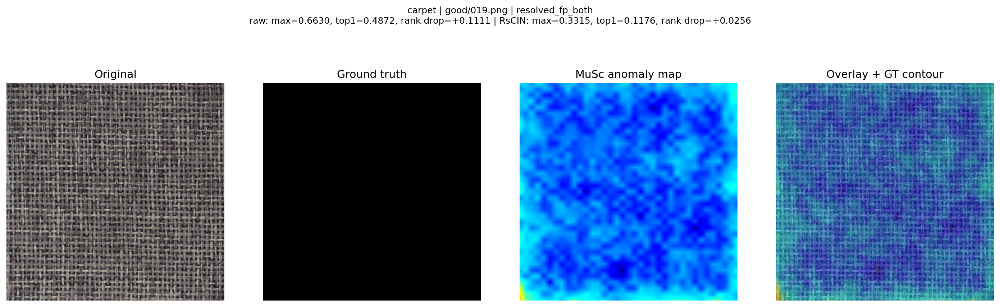

large_anomaly_rank_drop metal_contamination/013.png raw rank drop=+0.3504 RsCIN rank drop=+0.2393


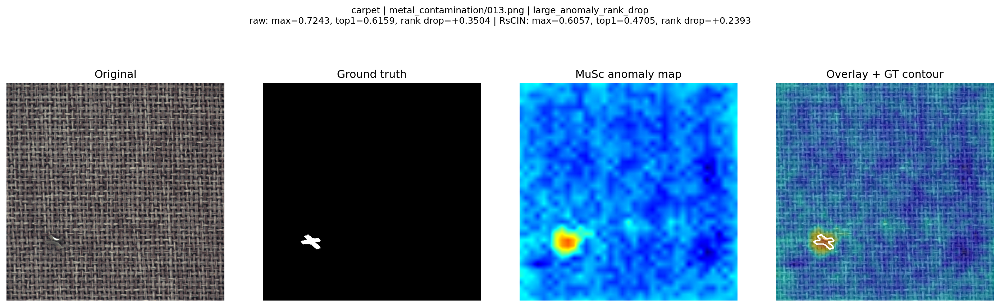

large_anomaly_rank_drop color/013.png raw rank drop=+0.1026 RsCIN rank drop=+0.2222


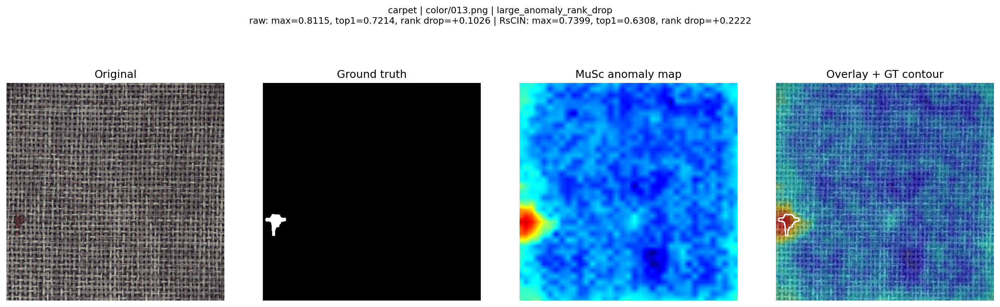


===== transistor =====
resolved_fp_raw_largest_drop good/022.png raw rank drop=+0.5000 RsCIN rank drop=+0.4300


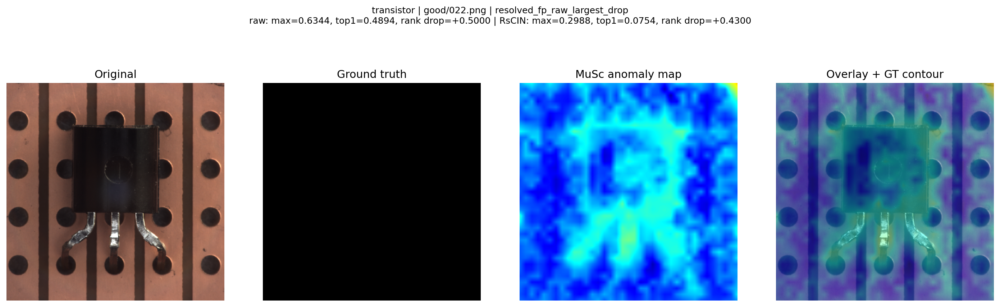

new_fp_both good/001.png raw rank drop=-0.1400 RsCIN rank drop=-0.1000


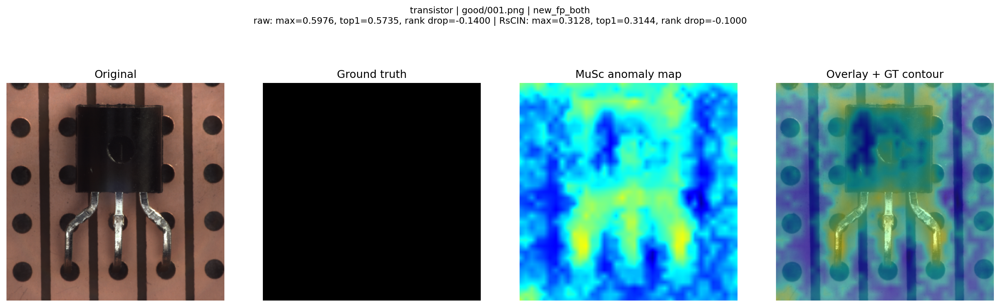

large_anomaly_rank_drop cut_lead/001.png raw rank drop=+0.1200 RsCIN rank drop=+0.0800


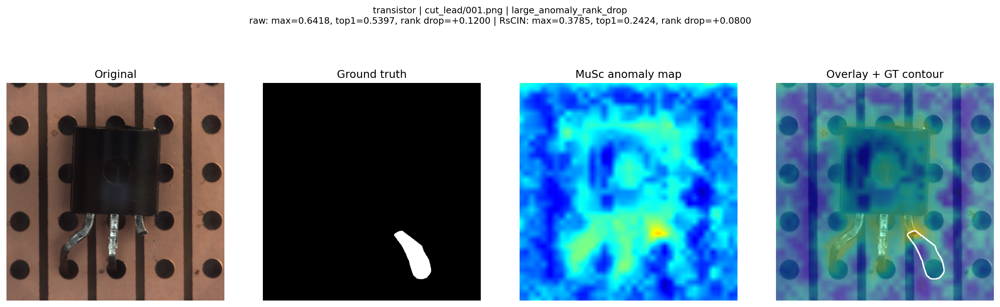


===== screw =====
new_fp_raw_largest_adverse_change good/008.png raw rank drop=-0.2687 RsCIN rank drop=-0.2313


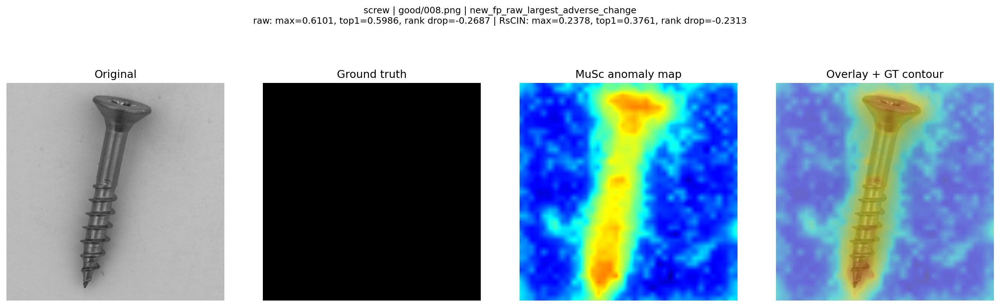

new_fp_rscin_largest_adverse_change good/003.png raw rank drop=-0.1000 RsCIN rank drop=-0.1125


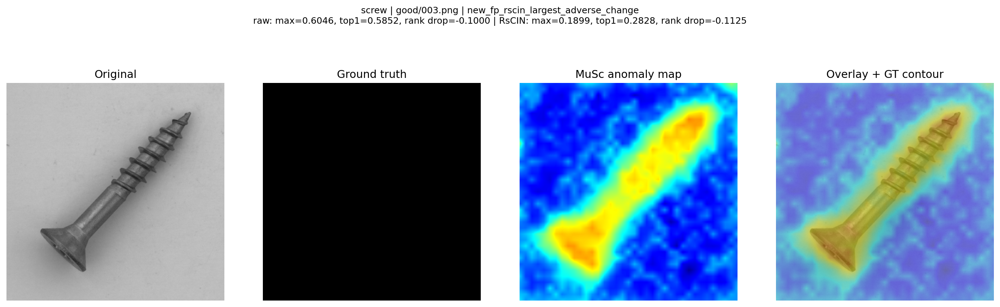

largest_rscin_anomaly_rank_drop scratch_neck/000.png raw rank drop=+0.4750 RsCIN rank drop=+0.6125


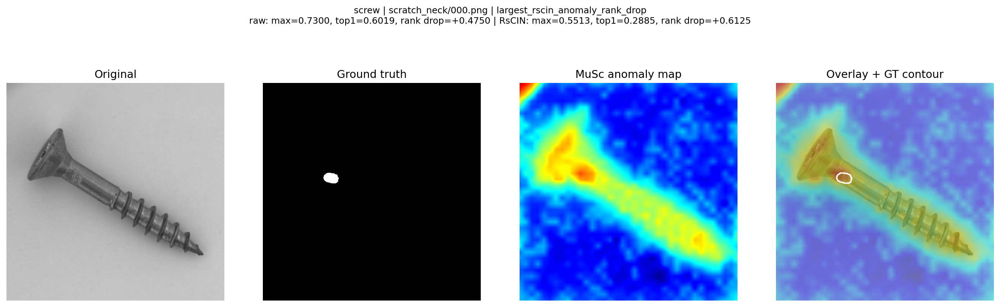

In [ ]:
from IPython.display import display

for category in QUAL_CATEGORIES:
    print(f"\n===== {category} =====")
    rows = asset_index[asset_index["category"] == category]
    for _, row in rows.iterrows():
        print(
            row["selection_reason"],
            row["relative_test_path"],
            f"raw rank drop={row['rank_drop_raw']:+.4f}",
            f"RsCIN rank drop={row['rank_drop_rscin']:+.4f}",
        )
        display(Image.open(row["panel_path"]))

In [ ]:
import zipfile

successful_attempts = {
    category: successful_qual_attempt(category)
    for category in QUAL_CATEGORIES
}
assert all(path is not None for path in successful_attempts.values())
assert len(asset_index) == 9
assert (asset_index.groupby("category").size() == 3).all()

metrics_records = [
    json.loads((attempt / "metrics.json").read_text(encoding="utf-8"))
    for attempt in successful_attempts.values()
]
assert sum(record["heatmap_count"] for record in metrics_records) == 377

max_metric_delta = max(
    record["max_absolute_metric_delta_from_e04"]
    for record in metrics_records
)
max_score_delta = max(
    value
    for record in metrics_records
    for value in record["max_absolute_per_image_score_delta_from_e04"].values()
)
assert max_metric_delta <= 0.05

summary_lines = [
    "# E04Q MVTec AD Pooling Qualitative Summary",
    "",
    f"- Run ID: `{RUN_ID}`",
    f"- Source E04 Run ID: `{SOURCE_E04_RUN_ID}`",
    f"- Categories: {', '.join(QUAL_CATEGORIES)}",
    f"- Heatmaps: {sum(record['heatmap_count'] for record in metrics_records)}",
    f"- Selected cases: {len(asset_index)}",
    f"- Maximum metric delta from E04: {max_metric_delta:.12g} percentage points",
    f"- Maximum per-image score delta from E04: {max_score_delta:.12g}",
    "",
    "## Review Status",
    "",
    "The panels are generated. Human qualitative interpretation remains pending until every panel is reviewed.",
]
(RUN_ROOT / "E04Q_SUMMARY.md").write_text(
    "\n".join(summary_lines) + "\n",
    encoding="utf-8",
)

done = {
    "run_id": RUN_ID,
    "source_e04_run_id": SOURCE_E04_RUN_ID,
    "completed_at_utc": datetime.now(timezone.utc).isoformat(),
    "categories": QUAL_CATEGORIES,
    "heatmap_count": int(sum(record["heatmap_count"] for record in metrics_records)),
    "selected_case_count": int(len(asset_index)),
    "max_absolute_metric_delta_from_e04": float(max_metric_delta),
    "max_absolute_per_image_score_delta_from_e04": float(max_score_delta),
    "status": "panels_generated_review_pending",
}
(RUN_ROOT / "E04Q_DONE.json").write_text(
    json.dumps(done, indent=2) + "\n",
    encoding="utf-8",
)

if (
    ACTIVE_Q_RUN_FILE.is_file()
    and ACTIVE_Q_RUN_FILE.read_text(encoding="utf-8").strip() == RUN_ID
):
    ACTIVE_Q_RUN_FILE.unlink()

zip_path = EXPORT_ROOT / f"{RUN_ID}.zip"
with zipfile.ZipFile(zip_path, "w", compression=zipfile.ZIP_DEFLATED) as archive:
    for path in RUN_ROOT.rglob("*"):
        if not path.is_file():
            continue
        relative = path.relative_to(RUN_ROOT)
        if "output" in relative.parts:
            continue
        archive.write(path, arcname=str(relative))

with zipfile.ZipFile(zip_path) as archive:
    bad_member = archive.testzip()
    assert bad_member is None, f"Damaged ZIP member: {bad_member}"
    names = archive.namelist()
    assert "E04Q_DONE.json" in names
    assert "selected-qualitative-cases.csv" in names
    assert "selected-assets-index.csv" in names
    assert len([name for name in names if name.endswith("/panel.png")]) == 9
    assert not any("/output/" in f"/{name}" for name in names)

print("E04Q panel generation is complete.")
print("ZIP:", zip_path)
print("ZIP size, MiB:", zip_path.stat().st_size / 2**20)

E04Q panel generation is complete.
ZIP: /content/drive/MyDrive/CS2203_MuSc/exports/20261017_082619_E04Q_mvtec_pooling_qualitative.zip
ZIP size, MiB: 17.488289833068848
